In [1]:
from pathlib import Path
import re
import warnings
import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.stats.multitest import multipletests
import seaborn as sns
from nilearn.datasets import fetch_atlas_harvard_oxford
from matplotlib import pyplot as plt
from scipy.stats import spearmanr
import json
from nilearn.plotting import plot_roi

In [2]:
config = json.load(open("../../config.json"))

In [50]:
config

{'data_dir': '/Volumes/T7/anpa_backup_from_labgpu/fmri_fasting_social_isolation/data'}

In [3]:
CONDITIONS = [
    "food_baseline",
    "social_baseline",
    "flowers_baseline",
    "food_fasting",
    "social_fasting",
    "flowers_fasting",
    "food_isolation",
    "social_isolation",
    "flowers_isolation",
]
STIMULUS = {condition: condition.split("_")[0] for condition in CONDITIONS}
SESSION = {condition: condition.split("_")[1] for condition in CONDITIONS}


# These are the two conditions whose stimulus matches the deprived need.
MOTIVATIONALLY_RELEVANT = {
    "food_fasting",
    "social_isolation",
}

In [4]:
def clean_roi_name(roi):
    """
    Remove a trailing .nii from ROI names while preserving spaces,
    commas, apostrophes, and underscores.
    """
    roi = str(roi).strip()

    if roi.endswith(".nii"):
        roi = roi[:-4]

    return roi

In [5]:
df = pd.read_csv('../../results_added_residuals/rdm_metadata.csv')
df['roi'] = df['roi'].apply(clean_roi_name)
df


,subject,roi,included,n_voxels,joint_coverage,common_runs
0,sub-SAXSISO01,Subcallosal Cortex,True,305,0.932722,"['run1', 'run2', 'run5', 'run6']"
1,sub-SAXSISO01,SNc_VTA,True,21,1.000000,"['run1', 'run2', 'run5', 'run6']"
2,sub-SAXSISO01,"Cingulate Gyrus, anterior division",True,724,1.000000,"['run1', 'run2', 'run5', 'run6']"
3,sub-SAXSISO01,Superior Frontal Gyrus,True,1657,0.980473,"['run1', 'run2', 'run5', 'run6']"
4,sub-SAXSISO01,"Temporal Fusiform Cortex, anterior division",False,29,0.177914,"['run1', 'run2', 'run5', 'run6']"
...,...,...,...,...,...,...
1947,sub-SAXSISO42,"Lateral Occipital Cortex, superior division",True,2658,0.994760,"['run1', 'run2', 'run3', 'run4', 'run5', 'run6']"
1948,sub-SAXSISO42,"Superior Temporal Gyrus, anterior division",True,165,1.000000,"['run1', 'run2', 'run3', 'run4', 'run5', 'run6']"
1949,sub-SAXSISO42,"Middle Temporal Gyrus, temporooccipital part",True,587,0.989882,"['run1', 'run2', 'run3', 'run4', 'run5', 'run6']"
1950,sub-SAXSISO42,"Middle Temporal Gyrus, anterior division",True,228,0.923077,"['run1', 'run2', 'run3', 'run4', 'run5', 'run6']"


In [6]:
# Lets add which dataset this roi came from so we wont mix them

midbrai_roi = roi_labels = ["Pu", "Ca", "NAC", "EXA", "GPe", "GPi", "RN", "SNr", "PBP", "VeP", "HN", "HTH", "MN", "STH", "SNc_VTA"]

cortical_roi = fetch_atlas_harvard_oxford("cort-maxprob-thr0-2mm").labels
subcortical_roi = fetch_atlas_harvard_oxford("sub-maxprob-thr0-2mm").labels

cortical_roi.remove("Background")
subcortical_roi.remove("Background")

subcortical_roi = [roi.removeprefix("Left ").removeprefix("Right ") for roi in subcortical_roi]

[fetch_atlas_harvard_oxford] Dataset found in /Users/anna/nilearn_data/fsl
[fetch_atlas_harvard_oxford] Dataset found in /Users/anna/nilearn_data/fsl


In [7]:
df['atlas'] = np.where(df['roi'].isin(cortical_roi), 'cortical', 
                       np.where(df['roi'].isin(subcortical_roi), 'subcortical', 
                                np.where(df['roi'].isin(midbrai_roi), 'midbrain', 'unknown')))

In [8]:
df.groupby('atlas')['roi'].nunique()

atlas
cortical       43
midbrain       15
subcortical     3
Name: roi, dtype: int64

In [9]:
df.query('included').groupby('atlas')['roi'].nunique()

atlas
cortical       42
midbrain       14
subcortical     3
Name: roi, dtype: int64

In [11]:
rdms = np.load('../../results_added_residuals/crossnobis_rdms.npz')
rdms.keys()

KeysView(NpzFile '../../results_added_residuals/crossnobis_rdms.npz' with keys: rdms, subjects, rois, conditions, analysis_settings)

In [12]:
display(
    df.query('included').groupby(['atlas', 'roi'])
    .agg(n_participants=('subject', 'nunique'))
    .reset_index()
    .sort_values(['atlas', 'n_participants'])
)


,atlas,roi,n_participants
33,cortical,Subcallosal Cortex,21
7,cortical,Frontal Orbital Cortex,25
8,cortical,Frontal Pole,31
12,cortical,"Inferior Temporal Gyrus, temporooccipital part",31
24,cortical,Occipital Pole,31
0,cortical,Angular Gyrus,32
1,cortical,Central Opercular Cortex,32
2,cortical,"Cingulate Gyrus, anterior division",32
3,cortical,"Cingulate Gyrus, posterior division",32
4,cortical,Cuneal Cortex,32


In [13]:
# looking at this we should exclude roi with little participants rdms

excluded_rois = (
    df.query('included')
    .groupby(['atlas', 'roi'])
    .agg(n_participants=('subject', 'nunique'))
    .reset_index()
    .query('n_participants < 20')  # for example, exclude ROIs with less than 5 participants
)

excluded_roi_list = excluded_rois.roi.to_list()
# Lets also exclude roi that are aggregation of other included roi
# Also roi that intersect across alases (Ca/Caudate, Pu/Putamen, NAC/Accumbens, GPe and GPI with Pallidum)
excluded_roi_list += ["Cerebral Cortex", "Cerebral White Matter", "Lateral Ventricle", "Brain-Stem", "Caudate", "Putamen", "Accumbens", "Pallidum"]
excluded_roi_list

['Cerebral Cortex',
 'Cerebral White Matter',
 'Lateral Ventricle',
 'Brain-Stem',
 'Caudate',
 'Putamen',
 'Accumbens',
 'Pallidum']

In [14]:
# Lets create model rdms

def make_pairwise_model(name, pair_function):
    """
    Construct a symmetric model RDM from a function that assigns a
    value to each pair of conditions.
    """
    model = pd.DataFrame(
        np.zeros((len(CONDITIONS), len(CONDITIONS))),
        index=CONDITIONS,
        columns=CONDITIONS,
        dtype=float,
    )

    for i, condition_1 in enumerate(CONDITIONS):
        for j in range(i + 1, len(CONDITIONS)):
            condition_2 = CONDITIONS[j]

            value = float(
                pair_function(condition_1, condition_2)
            )

            model.loc[condition_1, condition_2] = value
            model.loc[condition_2, condition_1] = value

    model.attrs["name"] = name
    return model


baseline_vs_deprived = make_pairwise_model(
    "baseline_vs_deprived",
    lambda a, b: (
        (SESSION[a] == 'baseline')
        !=
        (SESSION[b] == 'baseline')
    ),
)

isolation_vs_baseline_and_fasting = make_pairwise_model(
    "isolation_vs_baseline_and_fasting",
    lambda a, b: (
        (SESSION[a] == 'isolation')
        !=
        (SESSION[b] == 'isolation')
    ),
)

fasting_vs_baseline_and_isolation = make_pairwise_model(
    "fasting_vs_baseline_and_isolation",
    lambda a, b: (
        (SESSION[a] == 'fasting')
        !=
        (SESSION[b] == 'fasting')
    ),
)



social_vs_food_and_flowers = make_pairwise_model(
    "social_vs_food_and_flowers",
    lambda a, b: (
        (STIMULUS[a] == 'social')
        !=
        (STIMULUS[b] == 'social')
    ),
)

food_vs_social_and_flowers = make_pairwise_model(
    "food_vs_social_and_flowers",
    lambda a, b: (
        (STIMULUS[a] == 'food')
        !=
        (STIMULUS[b] == 'food')
    ),
)

flowers_vs_social_and_food = make_pairwise_model(
    "flowers_vs_social_and_food",
    lambda a, b: (
        (STIMULUS[a] == 'flowers')
        !=
        (STIMULUS[b] == 'flowers')
    ),
)


social_isolation_vs_rest_model = make_pairwise_model(
    "social_isolation_vs_rest",
    lambda a, b: (
        (a == 'social_isolation')
        !=
        (b == 'social_isolation')
    ),
)

food_fasting_vs_rest_model = make_pairwise_model(
    "food_fasting_vs_rest",
    lambda a, b: (
        (a == 'food_fasting')
        !=
        (b == 'food_fasting')
    ),
)

food_fasting_and_social_isolation_vs_rest = make_pairwise_model(
    "food_fasting_and_social_isolation_vs_rest",
    lambda a, b: (
        (a in ['food_fasting', 'social_isolation'])
        !=
        (b in ['food_fasting', 'social_isolation'])
    ),
)

In [15]:
#  Category-clustering models

    # 2.1 Stimulus family
        # social_vs_food_and_flowers
        # food_vs_social_and_flowers
        # flowers_vs_social_and_food

    # 2.2 Session family
        # baseline_vs_deprived
        # isolation_vs_baseline_and_fasting
        # fasting_vs_baseline_and_isolation

# Motivation deprivation models
    # social_isolation_vs_rest_model
    # food_fasting_vs_rest_model
    # food_fasting_and_social_isolation_vs_rest

MODEL_RDMS = {
    'Social cues vs. food and flower cues': social_vs_food_and_flowers,
    'Food cues vs. social and flower cues': food_vs_social_and_flowers,
    'Flower cues vs. social and food cues': flowers_vs_social_and_food,

    'Baseline vs. fasting and isolation': baseline_vs_deprived,
    'Isolation vs. baseline and fasting': isolation_vs_baseline_and_fasting,
    'Fasting vs. baseline and isolation': fasting_vs_baseline_and_isolation,

    'Social cues after isolation vs. all other conditions': social_isolation_vs_rest_model,
    'Food cues after fasting vs. all other conditions': food_fasting_vs_rest_model,
    'Deprivation-matched cues vs. all other conditions': food_fasting_and_social_isolation_vs_rest,
}

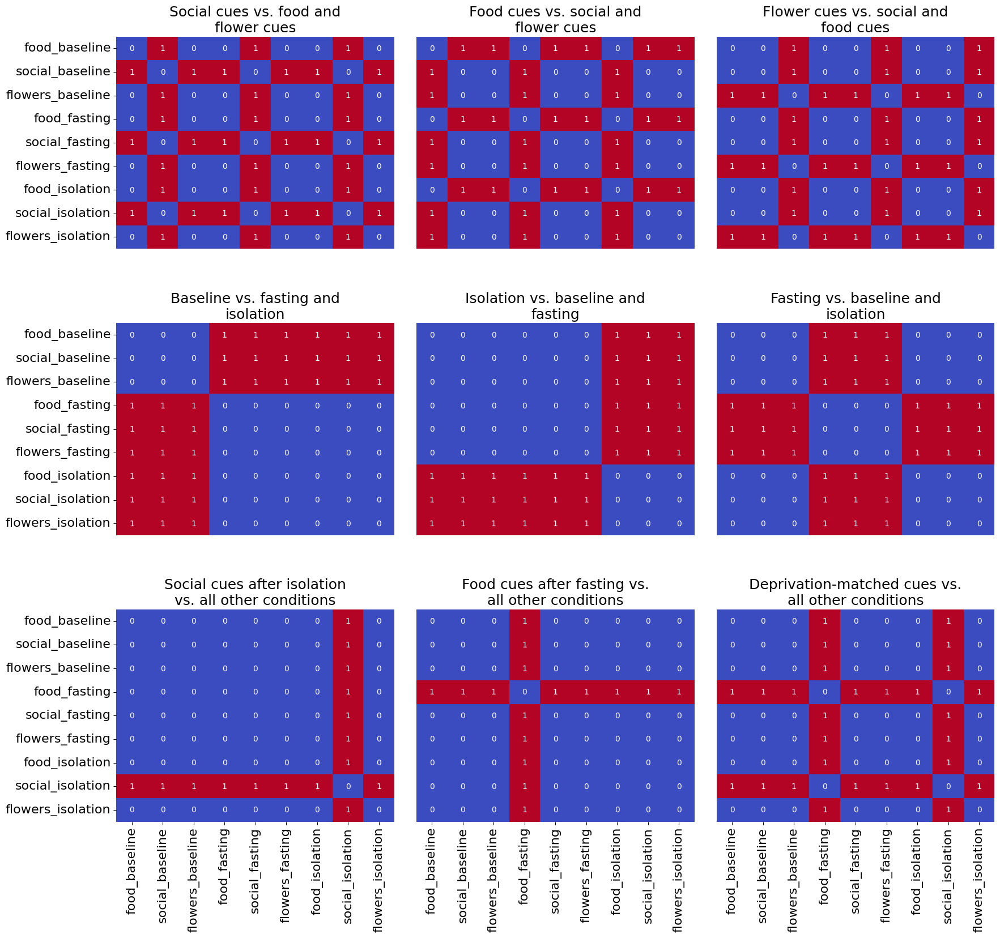

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns
import textwrap

fig, axes = plt.subplots(3, 3, figsize=(20, 18), sharex=True, sharey=True)

for idx, ((name, rdm), ax) in enumerate(zip(MODEL_RDMS.items(), axes.flatten())):
    row, col = divmod(idx, 3)

    sns.heatmap(
        rdm,
        annot=True,
        cmap="coolwarm",  # blue (low) -> red (high)
        cbar=False,       # no colour scale
        ax=ax,
    )

    ax.set_title(textwrap.fill(name, width=28), fontsize=18, fontweight="medium")  # wrap long titles

    if col != 0:
        ax.tick_params(left=False, labelleft=False)
    else:
        ax.tick_params(axis="y", labelsize=16, labelcolor="black")

    if row != 2:
        ax.tick_params(bottom=False, labelbottom=False)
    else:
        ax.tick_params(axis="x", labelsize=16, labelcolor="black", rotation=90)

plt.subplots_adjust(wspace=0.08, hspace=0.35)
fig.savefig("rdms.pdf", bbox_inches="tight")   # vector: stays sharp at any zoom
plt.show()

In [17]:
UPPER_TRIANGLE = np.triu_indices(
    len(CONDITIONS),
    k=1,
)

UPPER_TRIANGLE

(array([0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 3,
        3, 3, 3, 3, 4, 4, 4, 4, 5, 5, 5, 6, 6, 7]),
 array([1, 2, 3, 4, 5, 6, 7, 8, 2, 3, 4, 5, 6, 7, 8, 3, 4, 5, 6, 7, 8, 4,
        5, 6, 7, 8, 5, 6, 7, 8, 6, 7, 8, 7, 8, 8]))

In [18]:
def vectorize_rdm(rdm):
    """
    Return the 36 unique off-diagonal entries of a 9 x 9 RDM.
    """
    ordered = rdm.loc[CONDITIONS, CONDITIONS]
    return ordered.to_numpy(dtype=float)[UPPER_TRIANGLE]

In [19]:
def compare_rdm_to_models(neural_rdm, model_rdms=MODEL_RDMS):
    neural_vector = vectorize_rdm(neural_rdm)

    return pd.Series(
        {
            name: stats.spearmanr(
                neural_vector,
                vectorize_rdm(model_rdm),
            )[0]
            for name, model_rdm in model_rdms.items()
        },
        name="spearman_rho",
    )

In [20]:
rdms["rdms"][list(rdms["subjects"]).index("sub-SAXSISO01"), list(rdms["rois"]).index("Pu.nii")]

array([[ 0.        , -0.00028014, -0.00137852,  0.0003345 , -0.0003829 ,
         0.00519089,  0.01074568,  0.00840001,  0.0101301 ],
       [-0.00028014,  0.        ,  0.00477721,  0.00597187, -0.00256995,
        -0.0018298 ,  0.0057879 ,  0.00800014,  0.00974407],
       [-0.00137852,  0.00477721,  0.        ,  0.00627115,  0.00017662,
         0.0019571 ,  0.0122206 ,  0.00954974,  0.01128116],
       [ 0.0003345 ,  0.00597187,  0.00627115,  0.        ,  0.00824318,
         0.00632083,  0.00823496,  0.00836882,  0.01382787],
       [-0.0003829 , -0.00256995,  0.00017662,  0.00824318,  0.        ,
        -0.00071861,  0.00928361,  0.01051199,  0.01333746],
       [ 0.00519089, -0.0018298 ,  0.0019571 ,  0.00632083, -0.00071861,
         0.        ,  0.00431983,  0.00462567,  0.00474067],
       [ 0.01074568,  0.0057879 ,  0.0122206 ,  0.00823496,  0.00928361,
         0.00431983,  0.        ,  0.00451408, -0.00056179],
       [ 0.00840001,  0.00800014,  0.00954974,  0.00836882,  0

In [21]:
# Calculate one rho per participant, ROI, and model.
model_vectors = {
    name: vectorize_rdm(model_rdm)
    for name, model_rdm in MODEL_RDMS.items()
}

score_rows = []

valid_df = df.query('included & roi not in @excluded_roi_list')


for atlas, subject, roi in valid_df[['atlas', 'subject', 'roi']].itertuples(index=False):
    neural_rdm = rdms["rdms"][list(rdms["subjects"]).index(subject), list(rdms["rois"]).index(f"{roi}.nii")]
    neural_vector = neural_rdm[UPPER_TRIANGLE]

    for model_name, model_vector in model_vectors.items():
        rho = stats.spearmanr(neural_vector, model_vector)[0]

        score_rows.append({
            "atlas": atlas,
            "subject": subject,
            "roi": roi,
            "model": model_name,
            "rho": rho,
        })

participant_scores = pd.DataFrame(score_rows)
participant_scores

,atlas,subject,roi,model,rho
0,cortical,sub-SAXSISO01,Subcallosal Cortex,Social cues vs. food and flower cues,0.326222
1,cortical,sub-SAXSISO01,Subcallosal Cortex,Food cues vs. social and flower cues,-0.160437
2,cortical,sub-SAXSISO01,Subcallosal Cortex,Flower cues vs. social and food cues,-0.010696
3,cortical,sub-SAXSISO01,Subcallosal Cortex,Baseline vs. fasting and isolation,-0.213916
4,cortical,sub-SAXSISO01,Subcallosal Cortex,Isolation vs. baseline and fasting,0.074871
...,...,...,...,...,...
16618,cortical,sub-SAXSISO42,Central Opercular Cortex,Isolation vs. baseline and fasting,0.775445
16619,cortical,sub-SAXSISO42,Central Opercular Cortex,Fasting vs. baseline and isolation,0.240655
16620,cortical,sub-SAXSISO42,Central Opercular Cortex,Social cues after isolation vs. all other cond...,0.282999
16621,cortical,sub-SAXSISO42,Central Opercular Cortex,Food cues after fasting vs. all other conditions,0.057886


In [22]:
valid_df.roi.value_counts()

roi
Lateral Occipital Cortex, superior division                            32
Supramarginal Gyrus, anterior division                                 32
Pu                                                                     32
Parietal Opercular Cortex                                              32
Superior Temporal Gyrus, anterior division                             32
Supramarginal Gyrus, posterior division                                32
Middle Temporal Gyrus, temporooccipital part                           32
GPi                                                                    32
Precentral Gyrus                                                       32
Inferior Frontal Gyrus, pars triangularis                              32
VeP                                                                    32
STH                                                                    32
NAC                                                                    32
Lingual Gyrus                     

In [23]:
behavioral_df = pd.read_csv('../../dataframes/SISO_behavioral_data.csv')
behavioral_df['subject'] = behavioral_df['ID'].apply(lambda x: 'sub-' + x.replace('_', ''))


participant_scores['Loneliness_Score'] = participant_scores['subject'].map(behavioral_df.set_index('subject')['Loneliness_Score'])
participant_scores['Close_Relationships'] = participant_scores['subject'].map(behavioral_df.set_index('subject')['Close_Relationships'])
participant_scores['Monthly_Interactions'] = participant_scores['subject'].map(behavioral_df.set_index('subject')['Monthly_Interactions'])
participant_scores['Isolation_Lonely6'] = participant_scores['subject'].map(behavioral_df.set_index('subject')['Isolation_Lonely6'])

participant_scores.head()

,atlas,subject,roi,model,rho,Loneliness_Score,Close_Relationships,Monthly_Interactions,Isolation_Lonely6
0,cortical,sub-SAXSISO01,Subcallosal Cortex,Social cues vs. food and flower cues,0.326222,42,17,40,47
1,cortical,sub-SAXSISO01,Subcallosal Cortex,Food cues vs. social and flower cues,-0.160437,42,17,40,47
2,cortical,sub-SAXSISO01,Subcallosal Cortex,Flower cues vs. social and food cues,-0.010696,42,17,40,47
3,cortical,sub-SAXSISO01,Subcallosal Cortex,Baseline vs. fasting and isolation,-0.213916,42,17,40,47
4,cortical,sub-SAXSISO01,Subcallosal Cortex,Isolation vs. baseline and fasting,0.074871,42,17,40,47


In [24]:
participant_scores.model.unique()

array(['Social cues vs. food and flower cues',
       'Food cues vs. social and flower cues',
       'Flower cues vs. social and food cues',
       'Baseline vs. fasting and isolation',
       'Isolation vs. baseline and fasting',
       'Fasting vs. baseline and isolation',
       'Social cues after isolation vs. all other conditions',
       'Food cues after fasting vs. all other conditions',
       'Deprivation-matched cues vs. all other conditions'], dtype=object)

In [25]:
# Select one model.
baseline_scores = participant_scores.loc[
    participant_scores["model"] == "Social cues after isolation vs. all other conditions",
    ["atlas", "subject", "roi", "rho", "Loneliness_Score"],
].copy()

if baseline_scores.empty:
    raise ValueError("No rows found for Baseline vs. fasting and isolation.")

if baseline_scores[["atlas", "subject", "roi"]].isna().any().any():
    raise ValueError("Missing atlas, subject, or ROI identifiers.")

# Each participant should contribute at most one score per atlas and ROI.
duplicates = baseline_scores.duplicated(
    ["atlas", "roi", "subject"],
    keep=False,
)

if duplicates.any():
    display(
        baseline_scores.loc[duplicates].sort_values(
            ["atlas", "roi", "subject"]
        )
    )
    raise ValueError(
        "Duplicate participant scores found within an atlas and ROI."
    )

# Convert scores to numeric; invalid or missing values will be excluded.
for col in ["rho", "Loneliness_Score"]:
    baseline_scores[col] = pd.to_numeric(
        baseline_scores[col], errors="coerce"
    )
    baseline_scores[col] = baseline_scores[col].replace(
        [np.inf, -np.inf], np.nan
    )

results = []

for (atlas, roi), group in baseline_scores.groupby(["atlas", "roi"]):
    complete = group.dropna(subset=["rho", "Loneliness_Score"])
    n = len(complete)

    correlation = np.nan
    p_value = np.nan

    # Correlation is undefined if either variable is constant.
    if (
        n >= 3
        and complete["rho"].nunique() > 1
        and complete["Loneliness_Score"].nunique() > 1
    ):
        test = stats.spearmanr(
            complete["rho"],
            complete["Loneliness_Score"],
            alternative="two-sided",
        )
        correlation = test.statistic
        p_value = test.pvalue

    results.append({
        "atlas": atlas,
        "roi": roi,
        "n_participants": n,
        "n_excluded_missing": len(group) - n,
        "spearman_rho": correlation,
        "p_value": p_value,
    })

loneliness_results = pd.DataFrame(results)

# One FDR family: all valid ROI tests across all atlases.
loneliness_results["p_fdr"] = np.nan
valid = loneliness_results["p_value"].notna()

if valid.any():
    loneliness_results.loc[valid, "p_fdr"] = multipletests(
        loneliness_results.loc[valid, "p_value"],
        method="fdr_bh",
    )[1]

loneliness_results["significant_fdr_05"] = (
    loneliness_results["p_fdr"] < 0.05
)

loneliness_results.sort_values("p_value", na_position="last")

,atlas,roi,n_participants,n_excluded_missing,spearman_rho,p_value,p_fdr,significant_fdr_05
33,cortical,Subcallosal Cortex,21,0,-0.404837,0.068692,0.994821,False
2,cortical,"Cingulate Gyrus, anterior division",32,0,-0.264345,0.143737,0.994821,False
43,midbrain,EXA,32,0,-0.251035,0.165783,0.994821,False
7,cortical,Frontal Orbital Cortex,25,0,-0.274045,0.184966,0.994821,False
41,cortical,Temporal Occipital Fusiform Cortex,32,0,0.237496,0.190585,0.994821,False
52,midbrain,SNc_VTA,28,0,-0.223628,0.252650,0.994821,False
38,cortical,Supracalcarine Cortex,32,0,-0.204377,0.261851,0.994821,False
22,cortical,"Middle Temporal Gyrus, temporooccipital part",32,0,0.201527,0.268706,0.994821,False
29,cortical,Planum Temporale,32,0,0.198566,0.275950,0.994821,False
3,cortical,"Cingulate Gyrus, posterior division",32,0,-0.198290,0.276632,0.994821,False


In [26]:
# Select one model.
baseline_scores = participant_scores.loc[
    participant_scores["model"] == "Baseline vs. fasting and isolation",
    ["atlas", "subject", "roi", "rho", "Loneliness_Score"],
].copy()

if baseline_scores.empty:
    raise ValueError("No rows found for Baseline vs. fasting and isolation.")

if baseline_scores[["atlas", "subject", "roi"]].isna().any().any():
    raise ValueError("Missing atlas, subject, or ROI identifiers.")

# Each participant should contribute at most one score per atlas and ROI.
duplicates = baseline_scores.duplicated(
    ["atlas", "roi", "subject"],
    keep=False,
)

if duplicates.any():
    display(
        baseline_scores.loc[duplicates].sort_values(
            ["atlas", "roi", "subject"]
        )
    )
    raise ValueError(
        "Duplicate participant scores found within an atlas and ROI."
    )

# Convert scores to numeric; invalid or missing values will be excluded.
for col in ["rho", "Loneliness_Score"]:
    baseline_scores[col] = pd.to_numeric(
        baseline_scores[col], errors="coerce"
    )
    baseline_scores[col] = baseline_scores[col].replace(
        [np.inf, -np.inf], np.nan
    )

results = []

for (atlas, roi), group in baseline_scores.groupby(["atlas", "roi"]):
    complete = group.dropna(subset=["rho", "Loneliness_Score"])
    n = len(complete)

    correlation = np.nan
    p_value = np.nan

    # Correlation is undefined if either variable is constant.
    if (
        n >= 3
        and complete["rho"].nunique() > 1
        and complete["Loneliness_Score"].nunique() > 1
    ):
        test = stats.spearmanr(
            complete["rho"],
            complete["Loneliness_Score"],
            alternative="two-sided",
        )
        correlation = test.statistic
        p_value = test.pvalue

    results.append({
        "atlas": atlas,
        "roi": roi,
        "n_participants": n,
        "n_excluded_missing": len(group) - n,
        "spearman_rho": correlation,
        "p_value": p_value,
    })

loneliness_results = pd.DataFrame(results)

# One FDR family: all valid ROI tests across all atlases.
loneliness_results["p_fdr"] = np.nan
valid = loneliness_results["p_value"].notna()

if valid.any():
    loneliness_results.loc[valid, "p_fdr"] = multipletests(
        loneliness_results.loc[valid, "p_value"],
        method="fdr_bh",
    )[1]

loneliness_results["significant_fdr_05"] = (
    loneliness_results["p_fdr"] < 0.05
)

display(loneliness_results.sort_values("p_value", na_position="last"))

,atlas,roi,n_participants,n_excluded_missing,spearman_rho,p_value,p_fdr,significant_fdr_05
39,cortical,"Supramarginal Gyrus, anterior division",32,0,-0.350742,0.049047,0.841154,False
17,cortical,"Lateral Occipital Cortex, superior division",32,0,0.320336,0.073867,0.841154,False
1,cortical,Central Opercular Cortex,32,0,-0.298678,0.096813,0.841154,False
45,midbrain,GPi,32,0,0.285926,0.112646,0.841154,False
19,cortical,Middle Frontal Gyrus,32,0,-0.276833,0.125065,0.841154,False
57,subcortical,Hippocampus,31,0,0.273234,0.136948,0.841154,False
16,cortical,"Lateral Occipital Cortex, inferior division",32,0,0.266343,0.140620,0.841154,False
26,cortical,"Parahippocampal Gyrus, posterior division",32,0,0.258599,0.152976,0.841154,False
29,cortical,Planum Temporale,32,0,-0.258413,0.153283,0.841154,False
50,midbrain,Pu,32,0,-0.251058,0.165743,0.841154,False


In [27]:
summary_rows = []

rng = np.random.default_rng(42)
n_bootstrap = 10_000

for (atlas, roi, model), group in participant_scores.groupby(
    ["atlas", "roi", "model"]
):
    rhos = group["rho"].to_numpy(dtype=float)
    rhos = rhos[np.isfinite(rhos)]
    n = len(rhos)

    if n >= 2:
        # Arithmetic mean of participants' original Spearman correlations.
        mean_rho = np.mean(rhos)

        # Resample participants' scores, not individual RDM entries.
        bootstrap_result = stats.bootstrap(
            (rhos,),
            statistic=np.mean,
            n_resamples=n_bootstrap,
            confidence_level=0.95,
            method="percentile",
            random_state=rng,
        )

        ci_lower = bootstrap_result.confidence_interval.low
        ci_upper = bootstrap_result.confidence_interval.high

        # Two-sided test of whether the population mean raw rho is zero.
        test = stats.ttest_1samp(rhos, popmean=0)
        p_value = test.pvalue
    else:
        print(f"Not enough participants for atlas={atlas}, roi={roi}, model={model}")
        mean_rho = ci_lower = ci_upper = p_value = np.nan

    summary_rows.append({
        "atlas": atlas,
        "roi": roi,
        "model": model,
        "n_participants": n,
        "mean_rho": mean_rho,
        "ci_lower": ci_lower,
        "ci_upper": ci_upper,
        "p_value": p_value,
    })

model_summary = pd.DataFrame(summary_rows)

model_summary[ "p_fdr"] = multipletests(
            model_summary["p_value"],
            method="fdr_bh")[1]

In [28]:
participant_scores.query('roi == "Occipital Pole"')

,atlas,subject,roi,model,rho,Loneliness_Score,Close_Relationships,Monthly_Interactions,Isolation_Lonely6
288,cortical,sub-SAXSISO01,Occipital Pole,Social cues vs. food and flower cues,0.058827,42,17,40,47
289,cortical,sub-SAXSISO01,Occipital Pole,Food cues vs. social and flower cues,-0.106958,42,17,40,47
290,cortical,sub-SAXSISO01,Occipital Pole,Flower cues vs. social and food cues,-0.203220,42,17,40,47
291,cortical,sub-SAXSISO01,Occipital Pole,Baseline vs. fasting and isolation,0.000000,42,17,40,47
292,cortical,sub-SAXSISO01,Occipital Pole,Isolation vs. baseline and fasting,0.866360,42,17,40,47
...,...,...,...,...,...,...,...,...,...
16393,cortical,sub-SAXSISO42,Occipital Pole,Isolation vs. baseline and fasting,0.000000,43,6,41,50
16394,cortical,sub-SAXSISO42,Occipital Pole,Fasting vs. baseline and isolation,0.705923,43,6,41,50
16395,cortical,sub-SAXSISO42,Occipital Pole,Social cues after isolation vs. all other cond...,-0.160795,43,6,41,50
16396,cortical,sub-SAXSISO42,Occipital Pole,Food cues after fasting vs. all other conditions,0.173658,43,6,41,50


In [29]:
model_summary

,atlas,roi,model,n_participants,mean_rho,ci_lower,ci_upper,p_value,p_fdr
0,cortical,Angular Gyrus,Baseline vs. fasting and isolation,32,0.169963,0.113977,0.224449,1.524632e-06,4.906543e-06
1,cortical,Angular Gyrus,Deprivation-matched cues vs. all other conditions,32,0.133184,0.082104,0.186663,2.593211e-05,6.684443e-05
2,cortical,Angular Gyrus,Fasting vs. baseline and isolation,32,0.133196,0.065010,0.207068,1.095410e-03,1.985197e-03
3,cortical,Angular Gyrus,Flower cues vs. social and food cues,32,-0.163779,-0.183667,-0.139881,2.426536e-15,5.368711e-14
4,cortical,Angular Gyrus,Food cues after fasting vs. all other conditions,32,-0.023114,-0.070348,0.027742,3.673644e-01,4.168173e-01
...,...,...,...,...,...,...,...,...,...
526,subcortical,Thalamus,Food cues after fasting vs. all other conditions,32,-0.033164,-0.088844,0.025727,2.717725e-01,3.150900e-01
527,subcortical,Thalamus,Food cues vs. social and flower cues,32,-0.088240,-0.124172,-0.051641,4.988682e-05,1.187888e-04
528,subcortical,Thalamus,Isolation vs. baseline and fasting,32,0.332405,0.223605,0.439869,1.461431e-06,4.731830e-06
529,subcortical,Thalamus,Social cues after isolation vs. all other cond...,32,0.204410,0.118787,0.290636,7.271524e-05,1.636093e-04


In [30]:
model_summary.query('p_fdr < 0.01 & mean_rho > 0').sort_values("p_fdr")

,atlas,roi,model,n_participants,mean_rho,ci_lower,ci_upper,p_value,p_fdr
206,cortical,"Middle Temporal Gyrus, temporooccipital part",Social cues vs. food and flower cues,32,0.718123,0.666983,0.766588,2.786494e-23,4.660011e-21
116,cortical,"Inferior Temporal Gyrus, temporooccipital part",Social cues vs. food and flower cues,31,0.661932,0.609829,0.712306,1.891384e-21,2.008650e-19
377,cortical,Temporal Occipital Fusiform Cortex,Social cues vs. food and flower cues,32,0.613170,0.556177,0.670660,9.554524e-20,4.483142e-18
332,cortical,"Superior Temporal Gyrus, anterior division",Social cues vs. food and flower cues,32,0.659129,0.596458,0.719297,1.013139e-19,4.483142e-18
521,subcortical,Hippocampus,Social cues vs. food and flower cues,31,0.609316,0.551519,0.665555,2.584361e-19,1.055612e-17
...,...,...,...,...,...,...,...,...,...
519,subcortical,Hippocampus,Isolation vs. baseline and fasting,31,0.142151,0.051754,0.232379,4.876447e-03,7.894492e-03
20,cortical,"Cingulate Gyrus, anterior division",Fasting vs. baseline and isolation,32,0.137876,0.051641,0.225452,4.896891e-03,7.903493e-03
262,cortical,Planum Temporale,Deprivation-matched cues vs. all other conditions,32,0.077819,0.026564,0.128556,5.810444e-03,9.321287e-03
16,cortical,Central Opercular Cortex,Social cues after isolation vs. all other cond...,32,0.102708,0.033365,0.168231,6.046317e-03,9.670464e-03


In [31]:
(
    model_summary.query("p_fdr < 0.01 and mean_rho > 0")
    .sort_values("p_fdr")
    .groupby("model", as_index=False)
    .head(1)
    .sort_values("p_fdr")
)

,atlas,roi,model,n_participants,mean_rho,ci_lower,ci_upper,p_value,p_fdr
206,cortical,"Middle Temporal Gyrus, temporooccipital part",Social cues vs. food and flower cues,32,0.718123,0.666983,0.766588,2.786494e-23,4.660011e-21
122,cortical,Insular Cortex,Food cues vs. social and flower cues,32,0.405605,0.340761,0.472625,2.800182e-13,4.646552e-12
216,cortical,Occipital Pole,Baseline vs. fasting and isolation,31,0.506843,0.417822,0.591206,2.005867e-12,2.662788e-11
331,cortical,"Superior Temporal Gyrus, anterior division",Social cues after isolation vs. all other cond...,32,0.413845,0.337669,0.485002,4.977830e-12,6.293399e-11
209,cortical,Occipital Fusiform Gyrus,Fasting vs. baseline and isolation,32,0.439363,0.354465,0.525770,5.489949e-11,5.026143e-10
132,cortical,Intracalcarine Cortex,Isolation vs. baseline and fasting,32,0.478971,0.374349,0.579411,3.437158e-10,2.570607e-09
190,cortical,"Middle Temporal Gyrus, posterior division",Deprivation-matched cues vs. all other conditions,32,0.125642,0.085532,0.164209,6.955183e-07,2.413858e-06
274,cortical,Postcentral Gyrus,Food cues after fasting vs. all other conditions,32,0.166021,0.106320,0.225515,6.465227e-06,1.896705e-05


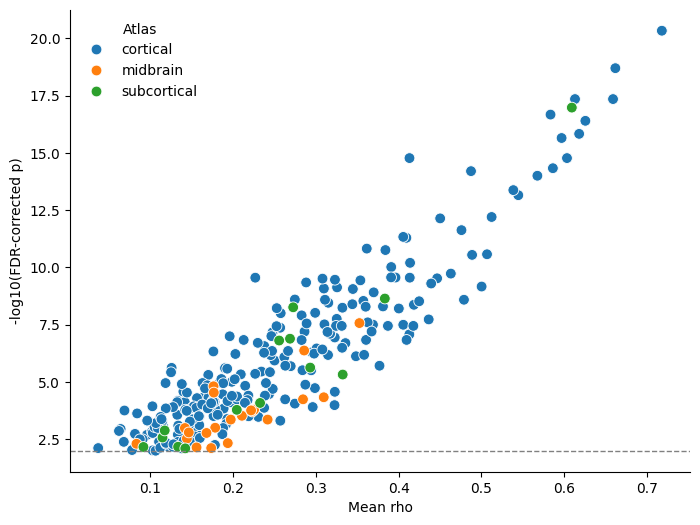

In [32]:
# plot significant rho values where axis are: rho value and fdr corrected p-value
# colored by the atlas

sig = model_summary.query("p_fdr < 0.01 and mean_rho > 0").copy()
sig["-log10 p_fdr"] = -np.log10(sig["p_fdr"])

colors = {"cortical": "tab:blue", "midbrain": "tab:orange", "subcortical": "tab:green"}

fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(
    data=sig, x="mean_rho", y="-log10 p_fdr",
    hue="atlas", palette=colors, s=60, ax=ax,
)
ax.axhline(-np.log10(0.01), ls="--", c="grey", lw=1)   # FDR 0.01 threshold
ax.set_xlabel("Mean rho")
ax.set_ylabel("-log10(FDR-corrected p)")
ax.legend(title="Atlas", frameon=False)
sns.despine()
plt.show()

In [33]:
# NEGATIVE RHO
model_summary.query('p_fdr < 0.01').query("mean_rho < 0.0")

,atlas,roi,model,n_participants,mean_rho,ci_lower,ci_upper,p_value,p_fdr
3,cortical,Angular Gyrus,Flower cues vs. social and food cues,32,-0.163779,-0.183667,-0.139881,2.426536e-15,5.368711e-14
12,cortical,Central Opercular Cortex,Flower cues vs. social and food cues,32,-0.170464,-0.195533,-0.146566,2.495111e-14,4.907052e-13
21,cortical,"Cingulate Gyrus, anterior division",Flower cues vs. social and food cues,32,-0.066849,-0.107125,-0.021392,5.092071e-03,8.193606e-03
39,cortical,Cuneal Cortex,Flower cues vs. social and food cues,32,-0.137876,-0.162275,-0.110635,1.451656e-11,1.712954e-10
41,cortical,Cuneal Cortex,Food cues vs. social and flower cues,32,-0.100607,-0.123336,-0.077712,1.142608e-09,6.973851e-09
66,cortical,Frontal Orbital Cortex,Flower cues vs. social and food cues,25,-0.170919,-0.207071,-0.131772,5.158860e-09,2.785614e-08
75,cortical,Frontal Pole,Flower cues vs. social and food cues,31,-0.163370,-0.195975,-0.125930,4.786988e-10,3.389187e-09
84,cortical,Heschl's Gyrus (includes H1 and H2),Flower cues vs. social and food cues,32,-0.133530,-0.163111,-0.104284,5.437998e-10,3.750100e-09
93,cortical,"Inferior Frontal Gyrus, pars opercularis",Flower cues vs. social and food cues,32,-0.128851,-0.163445,-0.094420,3.142498e-08,1.390555e-07
102,cortical,"Inferior Frontal Gyrus, pars triangularis",Flower cues vs. social and food cues,32,-0.146399,-0.176146,-0.115314,2.331345e-10,1.847678e-09


In [34]:
model_summary.query('p_fdr < 0.01 & mean_rho > 0').roi.value_counts()

roi
Supramarginal Gyrus, anterior division                                 8
Superior Parietal Lobule                                               8
Postcentral Gyrus                                                      8
Cingulate Gyrus, posterior division                                    7
Central Opercular Cortex                                               7
Inferior Frontal Gyrus, pars opercularis                               7
Inferior Temporal Gyrus, temporooccipital part                         7
Insular Cortex                                                         7
Juxtapositional Lobule Cortex (formerly Supplementary Motor Cortex)    7
Cingulate Gyrus, anterior division                                     7
Middle Frontal Gyrus                                                   7
Superior Temporal Gyrus, posterior division                            6
Parietal Opercular Cortex                                              6
Paracingulate Gyrus                            

In [35]:
model_summary.model.unique()

array(['Baseline vs. fasting and isolation',
       'Deprivation-matched cues vs. all other conditions',
       'Fasting vs. baseline and isolation',
       'Flower cues vs. social and food cues',
       'Food cues after fasting vs. all other conditions',
       'Food cues vs. social and flower cues',
       'Isolation vs. baseline and fasting',
       'Social cues after isolation vs. all other conditions',
       'Social cues vs. food and flower cues'], dtype=object)

In [36]:
model_summary.query('p_fdr < 0.01 and mean_rho > 0').query('model == "Deprivation-matched cues vs. all other conditions"').sort_values('p_fdr')

,atlas,roi,model,n_participants,mean_rho,ci_lower,ci_upper,p_value,p_fdr
190,cortical,"Middle Temporal Gyrus, posterior division",Deprivation-matched cues vs. all other conditions,32,0.125642,0.085532,0.164209,6.955183e-07,0.000002
271,cortical,Postcentral Gyrus,Deprivation-matched cues vs. all other conditions,32,0.124956,0.085871,0.164723,1.140770e-06,0.000004
307,cortical,Superior Frontal Gyrus,Deprivation-matched cues vs. all other conditions,32,0.185806,0.123756,0.248027,2.321321e-06,0.000007
73,cortical,Frontal Pole,Deprivation-matched cues vs. all other conditions,31,0.183838,0.122794,0.246296,3.404106e-06,0.000011
46,cortical,Frontal Medial Cortex,Deprivation-matched cues vs. all other conditions,32,0.163009,0.105930,0.219749,3.591989e-06,0.000011
325,cortical,"Superior Temporal Gyrus, anterior division",Deprivation-matched cues vs. all other conditions,32,0.137983,0.089471,0.186149,4.058840e-06,0.000012
100,cortical,"Inferior Frontal Gyrus, pars triangularis",Deprivation-matched cues vs. all other conditions,32,0.168837,0.111415,0.228662,4.643501e-06,0.000014
118,cortical,Insular Cortex,Deprivation-matched cues vs. all other conditions,32,0.139869,0.088961,0.190263,9.008689e-06,0.000026
181,cortical,"Middle Temporal Gyrus, anterior division",Deprivation-matched cues vs. all other conditions,32,0.144154,0.091875,0.197637,1.019577e-05,0.000029
64,cortical,Frontal Orbital Cortex,Deprivation-matched cues vs. all other conditions,25,0.187369,0.121110,0.253629,1.234619e-05,0.000035


In [37]:
model_summary.query('p_fdr < 0.01 and mean_rho > 0').query('model == "Baseline vs. fasting and isolation"').sort_values('p_fdr')

,atlas,roi,model,n_participants,mean_rho,ci_lower,ci_upper,p_value,p_fdr
216,cortical,Occipital Pole,Baseline vs. fasting and isolation,31,0.506843,0.417822,0.591206,2.005867e-12,2.662788e-11
153,cortical,"Lateral Occipital Cortex, superior division",Baseline vs. fasting and isolation,32,0.391065,0.318534,0.462765,7.765430e-12,9.589403e-11
207,cortical,Occipital Fusiform Gyrus,Baseline vs. fasting and isolation,32,0.463095,0.374019,0.549664,1.608294e-11,1.856531e-10
36,cortical,Cuneal Cortex,Baseline vs. fasting and isolation,32,0.413459,0.334741,0.494518,2.736995e-11,2.794893e-10
162,cortical,Lingual Gyrus,Baseline vs. fasting and isolation,32,0.446550,0.360143,0.531782,2.983597e-11,2.989226e-10
315,cortical,Superior Parietal Lobule,Baseline vs. fasting and isolation,32,0.308006,0.250014,0.367505,3.127354e-11,3.075232e-10
144,cortical,"Lateral Occipital Cortex, inferior division",Baseline vs. fasting and isolation,32,0.353797,0.285444,0.424661,3.861052e-11,3.661104e-10
288,cortical,Precuneous Cortex,Baseline vs. fasting and isolation,32,0.344104,0.269066,0.419476,5.925358e-10,4.033802e-09
270,cortical,Postcentral Gyrus,Baseline vs. fasting and isolation,32,0.252688,0.196531,0.308507,9.579395e-10,5.984304e-09
126,cortical,Intracalcarine Cortex,Baseline vs. fasting and isolation,32,0.405605,0.306832,0.505544,6.102379e-09,3.176827e-08


In [38]:
model_summary.query('p_fdr < 0.01 and mean_rho > 0').query('model == "Fasting vs. baseline and isolation"').sort_values('p_fdr')

,atlas,roi,model,n_participants,mean_rho,ci_lower,ci_upper,p_value,p_fdr
209,cortical,Occipital Fusiform Gyrus,Fasting vs. baseline and isolation,32,0.439363,0.354465,0.525770,5.489949e-11,5.026143e-10
218,cortical,Occipital Pole,Fasting vs. baseline and isolation,31,0.500287,0.399712,0.599310,7.700616e-11,6.815045e-10
146,cortical,"Lateral Occipital Cortex, inferior division",Fasting vs. baseline and isolation,32,0.309677,0.247507,0.373016,9.887690e-11,8.333910e-10
272,cortical,Postcentral Gyrus,Fasting vs. baseline and isolation,32,0.274581,0.214747,0.331570,3.263602e-10,2.511554e-09
38,cortical,Cuneal Cortex,Fasting vs. baseline and isolation,32,0.418473,0.326556,0.510557,6.354151e-10,4.270955e-09
164,cortical,Lingual Gyrus,Fasting vs. baseline and isolation,32,0.436355,0.331236,0.539139,3.322475e-09,1.857089e-08
290,cortical,Precuneous Cortex,Fasting vs. baseline and isolation,32,0.324384,0.245331,0.406106,7.037714e-09,3.553322e-08
155,cortical,"Lateral Occipital Cortex, superior division",Fasting vs. baseline and isolation,32,0.317532,0.238483,0.401097,1.601178e-08,7.524120e-08
128,cortical,Intracalcarine Cortex,Fasting vs. baseline and isolation,32,0.412958,0.306163,0.521420,1.813007e-08,8.371364e-08
281,cortical,Precentral Gyrus,Fasting vs. baseline and isolation,32,0.282770,0.207561,0.357139,3.446513e-08,1.475886e-07


In [39]:
model_summary.query('p_fdr < 0.01 and mean_rho > 0').query('model == "Isolation vs. baseline and fasting"').sort_values('p_fdr')

,atlas,roi,model,n_participants,mean_rho,ci_lower,ci_upper,p_value,p_fdr
132,cortical,Intracalcarine Cortex,Isolation vs. baseline and fasting,32,0.478971,0.374349,0.579411,3.437158e-10,2.570607e-09
294,cortical,Precuneous Cortex,Isolation vs. baseline and fasting,32,0.424824,0.333742,0.517744,4.168123e-10,2.990910e-09
285,cortical,Precentral Gyrus,Isolation vs. baseline and fasting,32,0.400257,0.310345,0.488836,1.003428e-09,6.195587e-09
159,cortical,"Lateral Occipital Cortex, superior division",Isolation vs. baseline and fasting,32,0.288787,0.220434,0.358978,5.193518e-09,2.785614e-08
177,cortical,Middle Frontal Gyrus,Isolation vs. baseline and fasting,32,0.310345,0.234639,0.385053,5.749595e-09,3.053035e-08
42,cortical,Cuneal Cortex,Isolation vs. baseline and fasting,32,0.369005,0.281099,0.458754,5.986531e-09,3.147374e-08
348,cortical,Supracalcarine Cortex,Isolation vs. baseline and fasting,32,0.387054,0.294302,0.483818,7.093261e-09,3.553322e-08
213,cortical,Occipital Fusiform Gyrus,Isolation vs. baseline and fasting,32,0.367334,0.277251,0.461929,1.282213e-08,6.246376e-08
168,cortical,Lingual Gyrus,Isolation vs. baseline and fasting,32,0.409616,0.301655,0.516574,3.345333e-08,1.456043e-07
141,cortical,Juxtapositional Lobule Cortex (formerly Supple...,Isolation vs. baseline and fasting,32,0.360649,0.266726,0.456414,3.319861e-08,1.456043e-07


In [40]:
model_summary.query('p_fdr < 0.01 and mean_rho > 0').query('model == "Food cues vs. social and flower cues"').sort_values('p_fdr')

,atlas,roi,model,n_participants,mean_rho,ci_lower,ci_upper,p_value,p_fdr
122,cortical,Insular Cortex,Food cues vs. social and flower cues,32,0.405605,0.340761,0.472625,2.800182e-13,4.646552e-12
356,cortical,"Supramarginal Gyrus, anterior division",Food cues vs. social and flower cues,32,0.311014,0.245335,0.377867,3.386687e-10,2.569044e-09
14,cortical,Central Opercular Cortex,Food cues vs. social and flower cues,32,0.282770,0.218763,0.347785,2.143822e-09,1.237358e-08
104,cortical,"Inferior Frontal Gyrus, pars triangularis",Food cues vs. social and flower cues,32,0.176146,0.126678,0.226450,1.189640e-07,4.644843e-07
68,cortical,Frontal Orbital Cortex,Food cues vs. social and flower cues,25,0.245362,0.182679,0.311467,1.817889e-07,6.703465e-07
275,cortical,Postcentral Gyrus,Food cues vs. social and flower cues,32,0.190185,0.131525,0.249680,7.237327e-07,2.479368e-06
59,cortical,Frontal Opercular Cortex,Food cues vs. social and flower cues,32,0.141552,0.087066,0.196711,2.997137e-05,7.542558e-05
239,cortical,"Parahippocampal Gyrus, posterior division",Food cues vs. social and flower cues,32,0.142221,0.084898,0.203387,7.123059e-05,1.614652e-04
23,cortical,"Cingulate Gyrus, anterior division",Food cues vs. social and flower cues,32,0.132528,0.075702,0.191024,1.246226e-04,2.712074e-04
95,cortical,"Inferior Frontal Gyrus, pars opercularis",Food cues vs. social and flower cues,32,0.114144,0.064342,0.172804,2.597209e-04,5.263809e-04


In [41]:
model_summary.query('p_fdr < 0.01 and mean_rho > 0').query('model == "Flower cues vs. social and food cues"').sort_values('p_fdr')

,atlas,roi,model,n_participants,mean_rho,ci_lower,ci_upper,p_value,p_fdr


In [42]:
model_summary.query('p_fdr < 0.01 and mean_rho > 0').query('model == "Social cues vs. food and flower cues"').sort_values('p_fdr')

,atlas,roi,model,n_participants,mean_rho,ci_lower,ci_upper,p_value,p_fdr
206,cortical,"Middle Temporal Gyrus, temporooccipital part",Social cues vs. food and flower cues,32,0.718123,0.666983,0.766588,2.786494e-23,4.660011e-21
116,cortical,"Inferior Temporal Gyrus, temporooccipital part",Social cues vs. food and flower cues,31,0.661932,0.609829,0.712306,1.891384e-21,2.008650e-19
377,cortical,Temporal Occipital Fusiform Cortex,Social cues vs. food and flower cues,32,0.613170,0.556177,0.670660,9.554524e-20,4.483142e-18
332,cortical,"Superior Temporal Gyrus, anterior division",Social cues vs. food and flower cues,32,0.659129,0.596458,0.719297,1.013139e-19,4.483142e-18
521,subcortical,Hippocampus,Social cues vs. food and flower cues,31,0.609316,0.551519,0.665555,2.584361e-19,1.055612e-17
98,cortical,"Inferior Frontal Gyrus, pars opercularis",Social cues vs. food and flower cues,32,0.583590,0.525932,0.641079,5.616936e-19,2.130423e-17
8,cortical,Angular Gyrus,Social cues vs. food and flower cues,32,0.625704,0.559691,0.686369,1.125942e-18,3.985835e-17
188,cortical,"Middle Temporal Gyrus, anterior division",Social cues vs. food and flower cues,32,0.618184,0.551836,0.681189,4.453358e-18,1.477958e-16
107,cortical,"Inferior Frontal Gyrus, pars triangularis",Social cues vs. food and flower cues,32,0.596959,0.531448,0.660967,7.182271e-18,2.243403e-16
161,cortical,"Lateral Occipital Cortex, superior division",Social cues vs. food and flower cues,32,0.413125,0.366832,0.462259,5.913847e-17,1.687619e-15


In [43]:
model_summary.query('p_fdr < 0.01 and mean_rho > 0').query('model == "Social cues after isolation vs. all other conditions"').sort_values('p_fdr')

,atlas,roi,model,n_participants,mean_rho,ci_lower,ci_upper,p_value,p_fdr
331,cortical,"Superior Temporal Gyrus, anterior division",Social cues after isolation vs. all other cond...,32,0.413845,0.337669,0.485002,4.977830e-12,6.293399e-11
151,cortical,"Lateral Occipital Cortex, inferior division",Social cues after isolation vs. all other cond...,32,0.288225,0.234358,0.345106,4.849250e-11,4.517459e-10
205,cortical,"Middle Temporal Gyrus, temporooccipital part",Social cues after isolation vs. all other cond...,32,0.325609,0.261291,0.389731,8.652864e-11,7.410760e-10
340,cortical,"Superior Temporal Gyrus, posterior division",Social cues after isolation vs. all other cond...,32,0.344704,0.273753,0.412845,1.054133e-10,8.746009e-10
7,cortical,Angular Gyrus,Social cues after isolation vs. all other cond...,32,0.357366,0.276969,0.431337,3.916625e-10,2.888511e-09
52,cortical,Frontal Medial Cortex,Social cues after isolation vs. all other cond...,32,0.381083,0.295455,0.463692,7.677422e-10,5.032976e-09
196,cortical,"Middle Temporal Gyrus, posterior division",Social cues after isolation vs. all other cond...,32,0.360180,0.277371,0.438975,7.991617e-10,5.175059e-09
115,cortical,"Inferior Temporal Gyrus, temporooccipital part",Social cues after isolation vs. all other cond...,31,0.257479,0.196891,0.312875,1.685603e-09,9.945058e-09
259,cortical,Planum Polare,Social cues after isolation vs. all other cond...,32,0.325207,0.246820,0.400781,3.108411e-09,1.755922e-08
187,cortical,"Middle Temporal Gyrus, anterior division",Social cues after isolation vs. all other cond...,32,0.362592,0.275753,0.448421,4.513676e-09,2.496627e-08


In [44]:
model_summary.query('roi == "SNc_VTA"').sort_values('p_fdr')

,atlas,roi,model,n_participants,mean_rho,ci_lower,ci_upper,p_value,p_fdr
471,midbrain,SNc_VTA,Flower cues vs. social and food cues,28,0.064366,0.018336,0.108677,0.010008,0.015227
474,midbrain,SNc_VTA,Isolation vs. baseline and fasting,28,0.119373,0.004775,0.235121,0.058067,0.075021
470,midbrain,SNc_VTA,Fasting vs. baseline and isolation,28,0.038390,-0.049473,0.128927,0.425990,0.475211
475,midbrain,SNc_VTA,Social cues after isolation vs. all other cond...,28,0.028943,-0.059040,0.114853,0.529785,0.572945
473,midbrain,SNc_VTA,Food cues vs. social and flower cues,28,-0.013561,-0.066085,0.039923,0.627799,0.668059
468,midbrain,SNc_VTA,Baseline vs. fasting and isolation,28,-0.014134,-0.131788,0.106385,0.820718,0.842943
469,midbrain,SNc_VTA,Deprivation-matched cues vs. all other conditions,28,0.007640,-0.060140,0.074244,0.827792,0.848567
476,midbrain,SNc_VTA,Social cues vs. food and flower cues,28,-0.003438,-0.061692,0.057108,0.913229,0.921910
472,midbrain,SNc_VTA,Food cues after fasting vs. all other conditions,28,-0.001608,-0.070290,0.065242,0.964452,0.969932


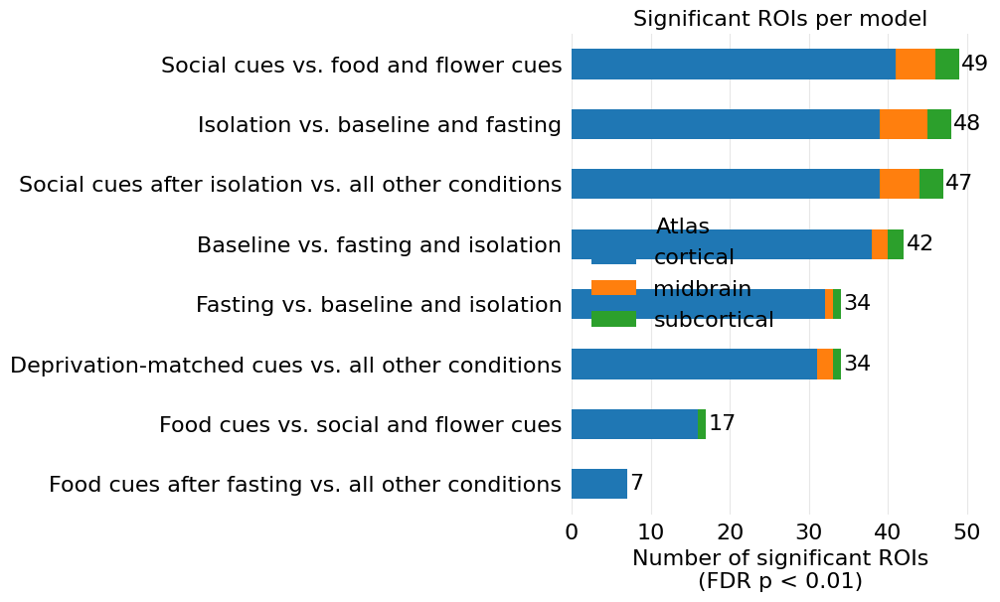

In [45]:
import matplotlib.pyplot as plt
import seaborn as sns

sig = model_summary.query("p_fdr < 0.01 and mean_rho > 0")

# 1) Number of significant ROIs per model (the value_counts from your screenshot)
# rows = model, columns = atlas, values = number of significant ROIs
counts = (
    sig.groupby(["model", "atlas"]).size().unstack(fill_value=0)
)
counts = counts.loc[counts.sum(axis=1).sort_values().index]  # largest bar on top
colors = {"cortical": "tab:blue", "midbrain": "tab:orange", "subcortical": "tab:green"}

ax = counts.plot(
    kind="barh", stacked=True, figsize=(10, 6),
    color=[colors[a] for a in counts.columns],
)

for i, total in enumerate(counts.sum(axis=1)):
    ax.text(total + 0.3, i, str(total), va="center")

ax.set_xlabel("Number of significant ROIs (FDR p < 0.01)")
ax.set_ylabel("")
ax.set_title("Significant ROIs per model")
ax.legend(title="atlas", frameon=False)

# remove the surrounding box
import seaborn as sns
sns.despine(left=True, bottom=True)
ax.tick_params(left=False, bottom=False)

# light vertical gridlines behind the bars, like the reference
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)

# Readable, regular-weight text at the final printed size.
from textwrap import fill

labels = [str(model).replace("_", " ") for model in counts.index]
ax.set_yticks(range(len(counts)))
ax.set_yticklabels(labels, fontsize=16, fontweight="medium")

ax.tick_params(axis="x", labelsize=16, colors="black")
ax.set_xlabel("Number of significant ROIs\n(FDR p < 0.01)",
              fontsize=16, color="black", fontweight="medium")
ax.set_title("Significant ROIs per model", fontsize=16, fontweight="medium")
ax.legend(title="Atlas", frameon=False, fontsize=16, title_fontsize=16)
for text in ax.texts:
    text.set_fontsize(16)
    text.set_color("black")
    text.set_fontweight("medium")
ax.margins(x=0.08)

plt.tight_layout(pad=0.5)
# save as pdf
plt.savefig("signif_roi_atlases.pdf", bbox_inches="tight")   
plt.show()


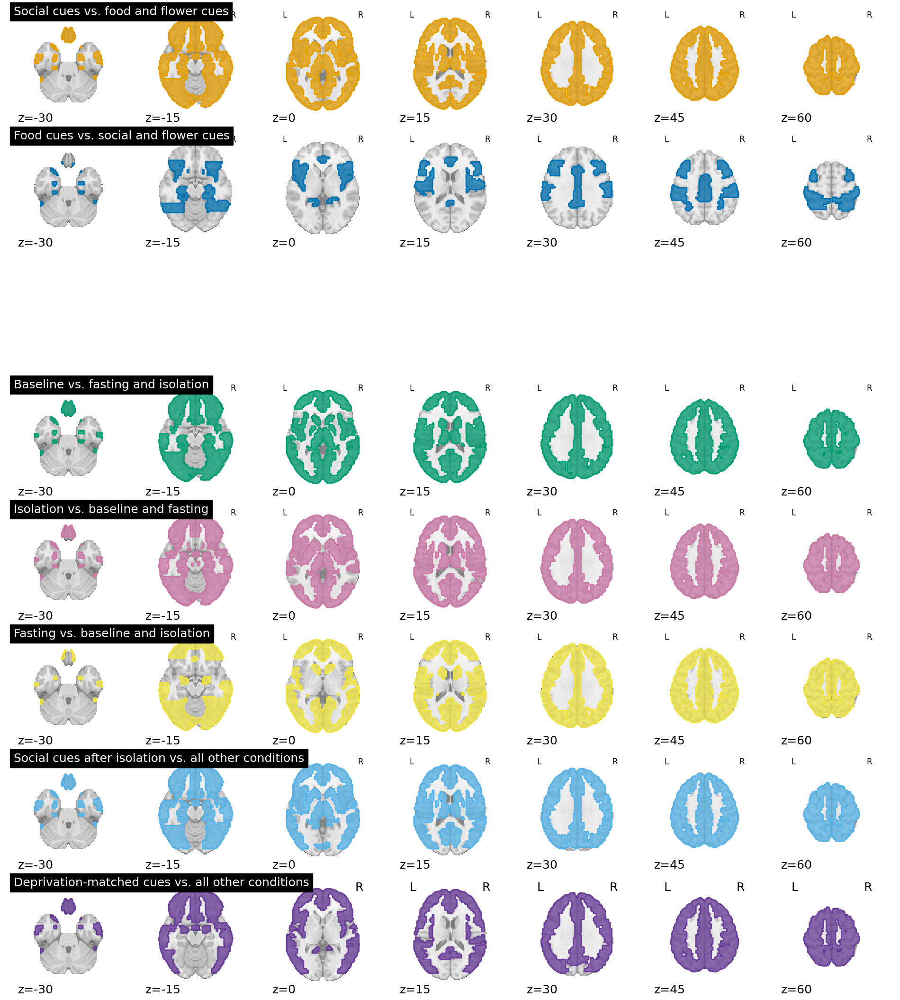

In [46]:
from pathlib import Path
import textwrap

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import nibabel as nib
import numpy as np
from nilearn import plotting
from nilearn.image import resample_to_img

mask_dir = Path("../../masks_MNI152NLin2009cAsym")  

# ------------------------------------------------------------
# SETTINGS
# ------------------------------------------------------------


p_threshold = 0.01

# These coordinates are in millimeters and assume MNI space.
# Adjust them if your masks and anatomical background are
# in a different space.
slice_positions = [-30, -15, 0, 15, 30, 45, 60]

# Set to a matching anatomical NIfTI image if not using MNI.
# None uses Nilearn's default MNI template.
background_image = None

# ------------------------------------------------------------
# SELECT SIGNIFICANT RESULTS
# ------------------------------------------------------------

#significant = model_summary.query('p_fdr < 0.01 & mean_rho > 0').sort_values("p_fdr")
significant = (
    model_summary.loc[
        (model_summary["p_fdr"] < p_threshold) & (model_summary["mean_rho"] > 0),
        ["roi", "model"]
    ]
    .dropna()
    .drop_duplicates()
)

if significant.empty:
    raise ValueError("No significant ROI–model pairs found.")

#models = sorted(significant["model"].unique())
models  = ['Social cues vs. food and flower cues', 
           'Food cues vs. social and flower cues',
           'Flower cues vs. social and food cues',
           'Baseline vs. fasting and isolation',
           'Isolation vs. baseline and fasting',
           'Fasting vs. baseline and isolation',
           'Social cues after isolation vs. all other conditions',
           'Deprivation-matched cues vs. all other conditions']

rois = sorted(significant["roi"].unique())

# ------------------------------------------------------------
# FIND ROI MASKS
# ------------------------------------------------------------

def mask_name(path):
    if path.name.endswith(".nii.gz"):
        return path.name[:-7]
    if path.name.endswith(".nii"):
        return path.name[:-4]
    return None


mask_files = {}

for path in mask_dir.iterdir():
    name = mask_name(path)
    if name is not None:
        if name in mask_files:
            raise ValueError(f"Multiple masks found for: {name}")
        mask_files[name] = path

missing = [roi for roi in rois if roi not in mask_files]

if missing:
    raise FileNotFoundError(
        "Masks not found for:\n" + "\n".join(missing)
    )

# ------------------------------------------------------------
# LOAD MASKS ON A COMMON GRID
# ------------------------------------------------------------

#reference = nib.load(str(mask_files[rois[0]]))
from nilearn import datasets
reference = datasets.load_mni152_template()

# Beta maps are MNI152NLin2009cAsym (fMRIPrep), same as Nilearn's template.
# The Harvard-Oxford maxprob-thr0 masks are unthresholded and extend into CSF/skull,
# so clip them to the brain for display.
brain_mask = np.asarray(
    resample_to_img(datasets.load_mni152_brain_mask(), reference, interpolation="nearest").dataobj
) > 0

if len(reference.shape) != 3:
    raise ValueError("Expected 3D ROI masks.")

roi_masks = {}

for roi in rois:
    mask = nib.load(str(mask_files[roi]))

    if len(mask.shape) != 3:
        raise ValueError(f"Mask for {roi} is not 3D.")

    if (
        mask.shape != reference.shape
        or not np.allclose(mask.affine, reference.affine)
    ):
        mask = resample_to_img(
            mask,
            reference,
            interpolation="nearest",
        )

    # Assumes binary masks with values 0 and 1.
    roi_masks[roi] = (np.asarray(mask.dataobj) > 0.5) & brain_mask

# ------------------------------------------------------------
# PLOT ONE ROW PER MODEL
# ------------------------------------------------------------
# ------------------------------------------------------------
# PLOT ONE ROW PER MODEL — MANUALLY POSITIONED
# ------------------------------------------------------------

from matplotlib.colors import ListedColormap

if len(models) > 20:
    raise ValueError("More than 20 models: choose a larger color palette.")

#colors = plt.get_cmap("tab20").colors
# Saturated, distinct colors (Okabe-Ito style + extras), up to 12 models
colors = [
    "#E69F00",  # orange
    "#0072B2",  # blue
    "#D55E00",  # vermilion
    "#009E73",  # green
    "#CC79A7",  # pink
    "#F0E442",  # yellow
    "#56B4E9",  # sky blue
    "#6A3D9A",  # purple
    "#B15928",  # brown
    "#1B1B1B",  # near-black
    "#E31A1C",  # red
    "#33A02C",  # dark green
]
if len(models) > len(colors):
    raise ValueError("More models than colors; extend the list.")
n_models = len(models)

fig = plt.figure(figsize=(20, 3 * (n_models-1)))

# Leave a small gap between rows.
row_height = 1 / n_models
gap = 0.02 * row_height

for i, model in enumerate(models):
    color = colors[i]

    model_rois = significant.loc[
        significant["model"] == model, "roi"
    ].unique()

    combined = np.zeros(reference.shape, dtype=np.uint8)

    for roi in model_rois:
        combined[roi_masks[roi]] = 1

    if not combined.any():
        print(f"Warning: no mask voxels found for {model}")
        continue

    combined_img = nib.Nifti1Image(combined, reference.affine)

    # Place each row before Nilearn creates its slice axes.
    bottom = 1 - (i + 1) * row_height + gap
    ax = fig.add_axes([
        0.03,                  # left
        bottom,                # bottom
        0.94,                  # width
        row_height - 2 * gap,  # height
    ])

    plot_kwargs = {
        "display_mode": "z",
        "cut_coords": slice_positions,
        "figure": fig,
        "axes": ax,
        # "title": model.replace("_", " "),
        "draw_cross": False,
        "black_bg": False,
        "colorbar": False
    }

    # Omit anat_img for Nilearn's default MNI template.
    if background_image is not None:
        plot_kwargs["anat_img"] = background_image

    display = plotting.plot_anat(**plot_kwargs)

    display.add_overlay(
            combined_img,
            cmap=ListedColormap([color]),
            threshold=0.5,
            vmin=0,
            vmax=1,
            transparency=0.75,   # was 0.35
            interpolation="nearest",
        )
    display.title(model.replace("_", " "), size=18)   # bigger black-box title
    # L/R labels only on the last row, so they don't collide with the titles
    display.annotate(size=18, left_right=(i == n_models - 1))

    display.add_contours(
        combined_img,
        levels=[0.5],
        colors=[color],
        linewidths=2.0,      # was 1.2
    )

plt.savefig("rdms_roi_brain.pdf", bbox_inches="tight")
plt.show()


food, baseline: food_baseline
food, fasting: food_fasting
social, baseline: social_baseline
social, isolation: social_isolation
flowers, baseline: flowers_baseline
flowers, fasting: flowers_fasting


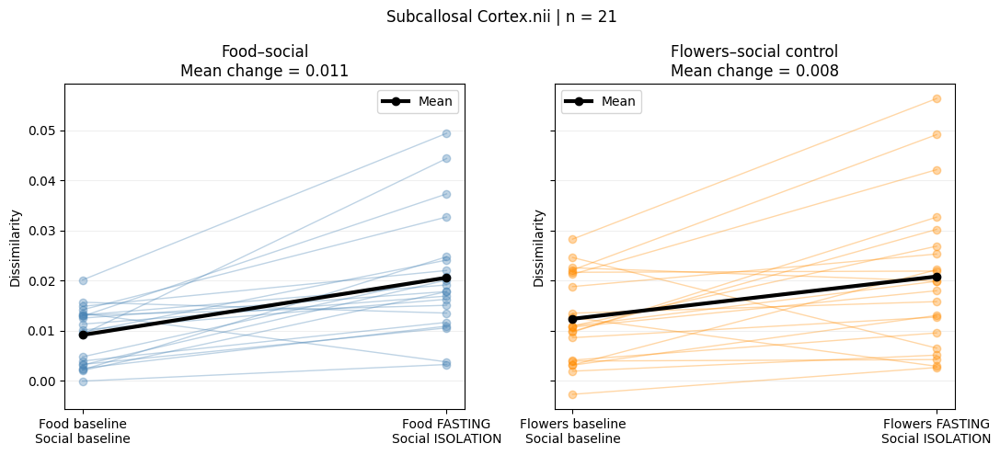

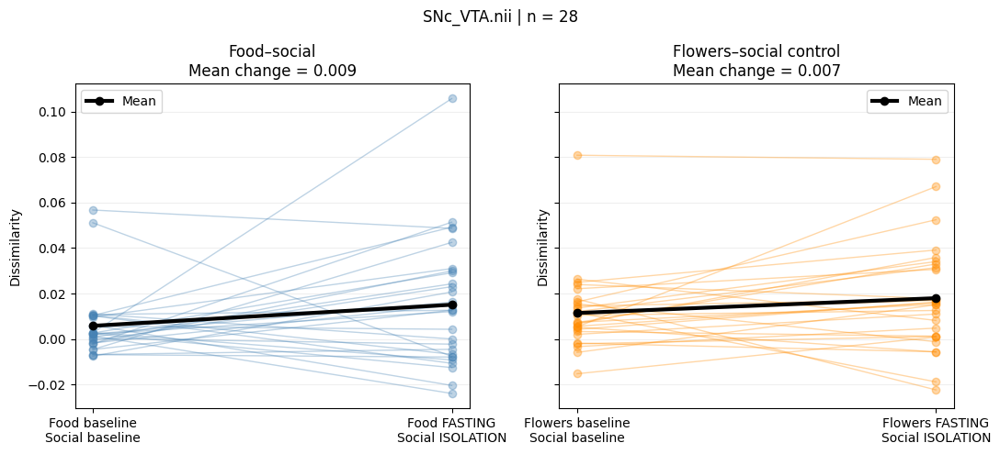

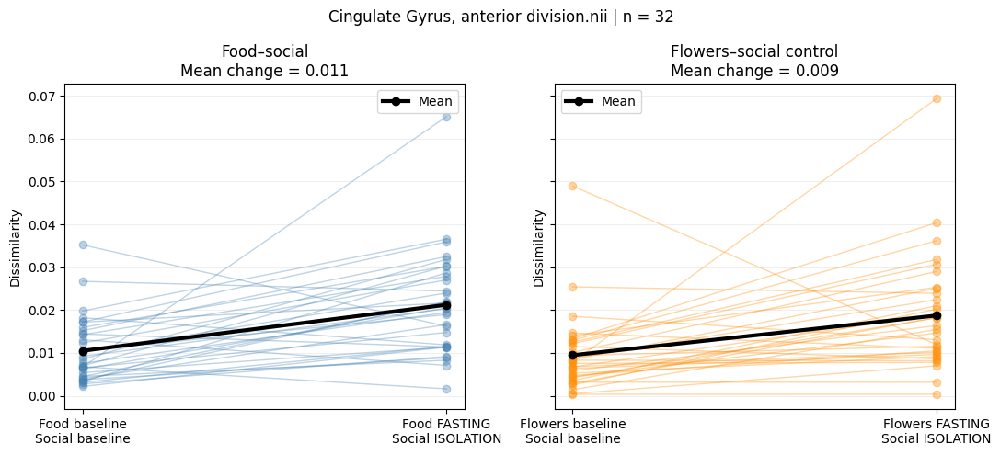

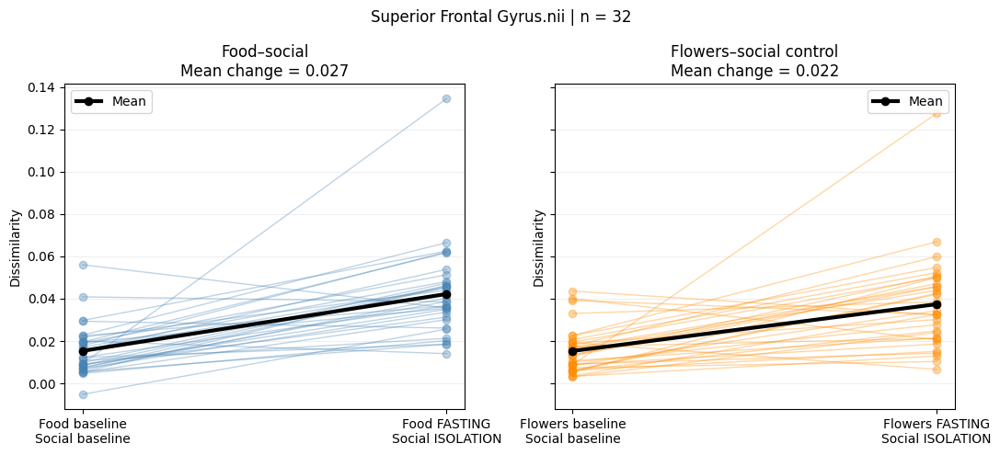

Skipping Temporal Fusiform Cortex, anterior division.nii: insufficient complete pairs.
Skipping HN.nii: insufficient complete pairs.


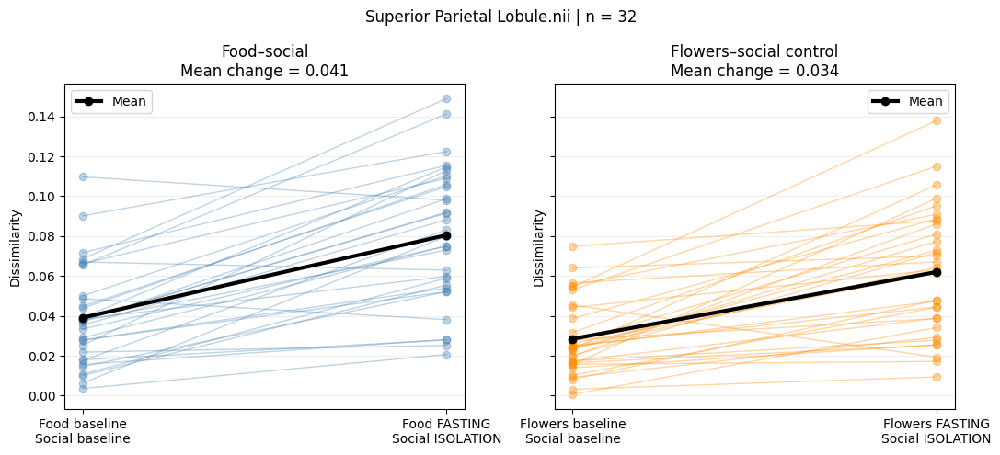

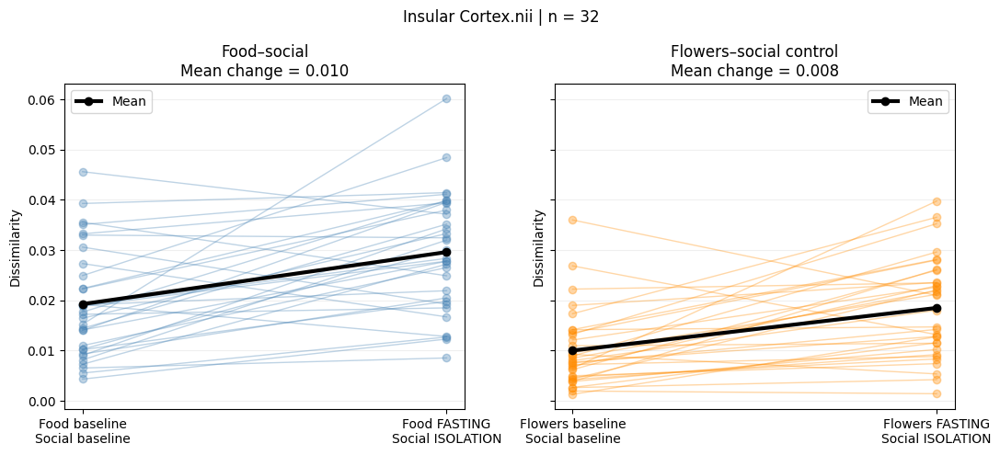

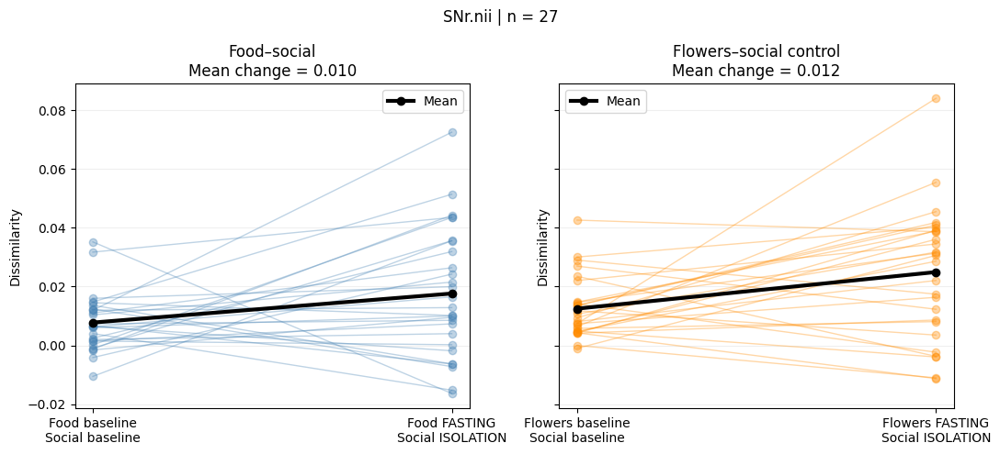

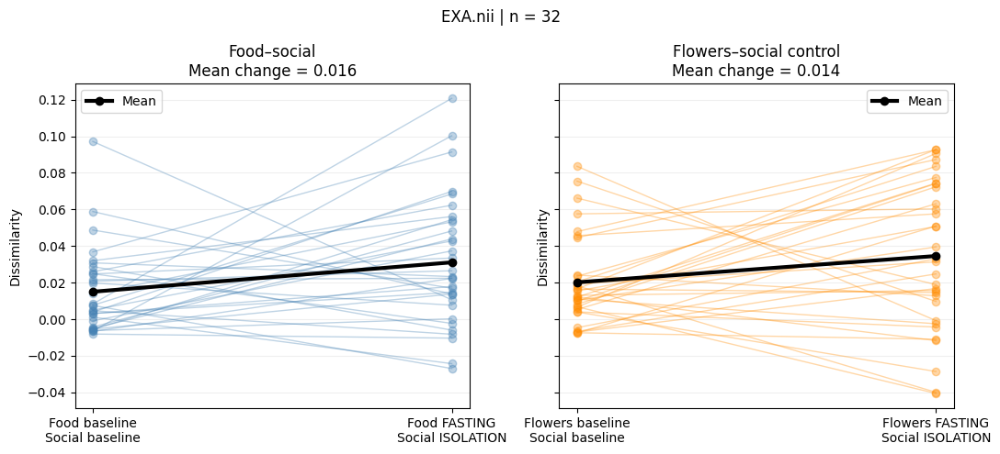

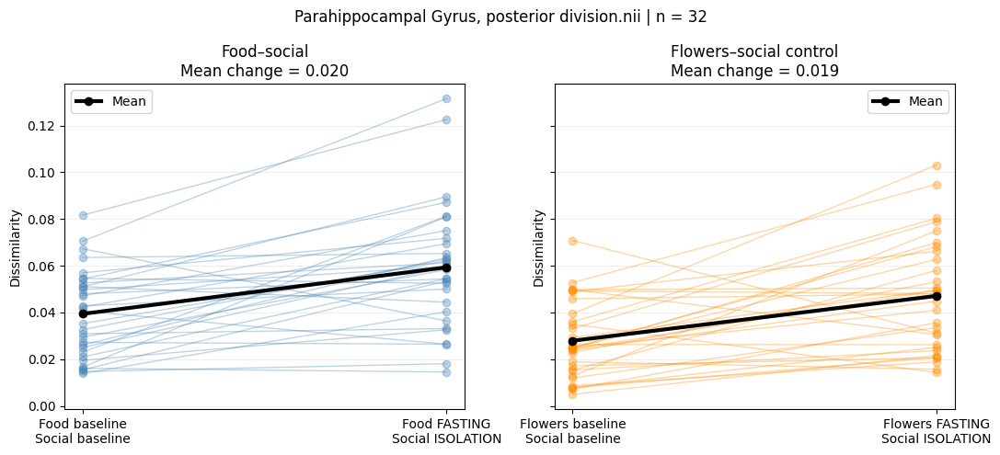

...

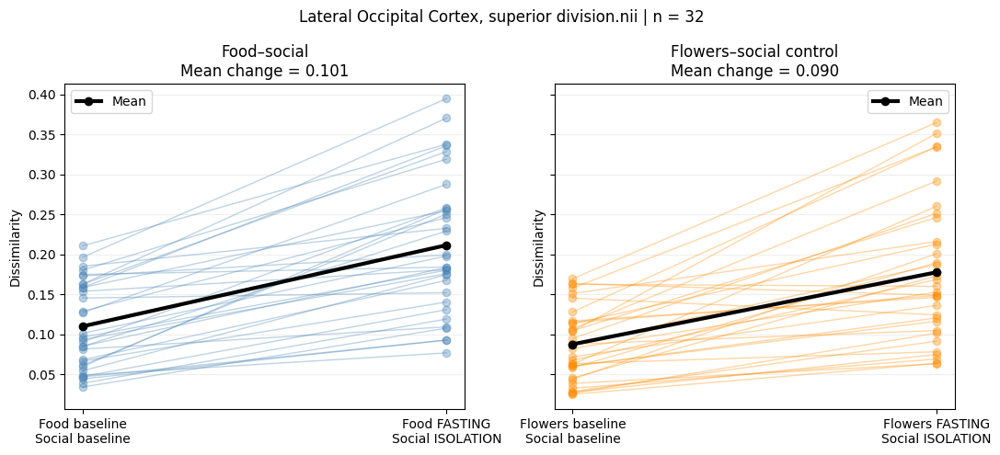

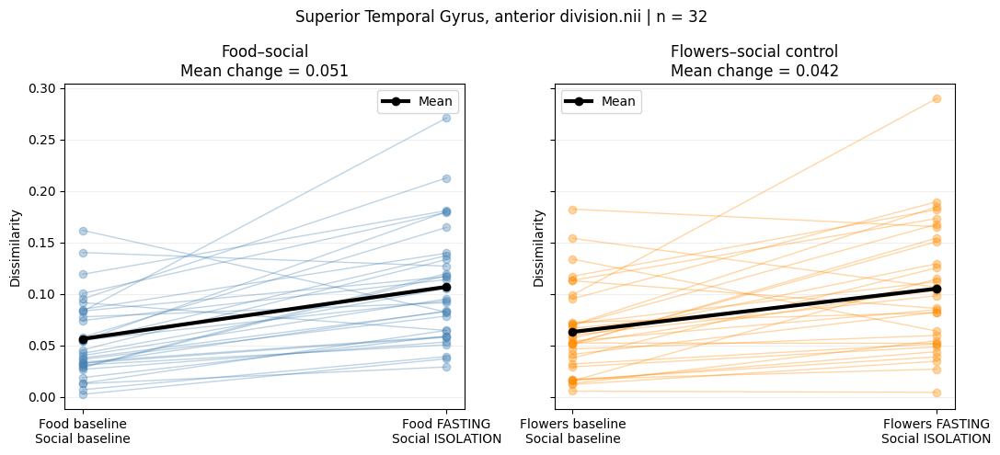

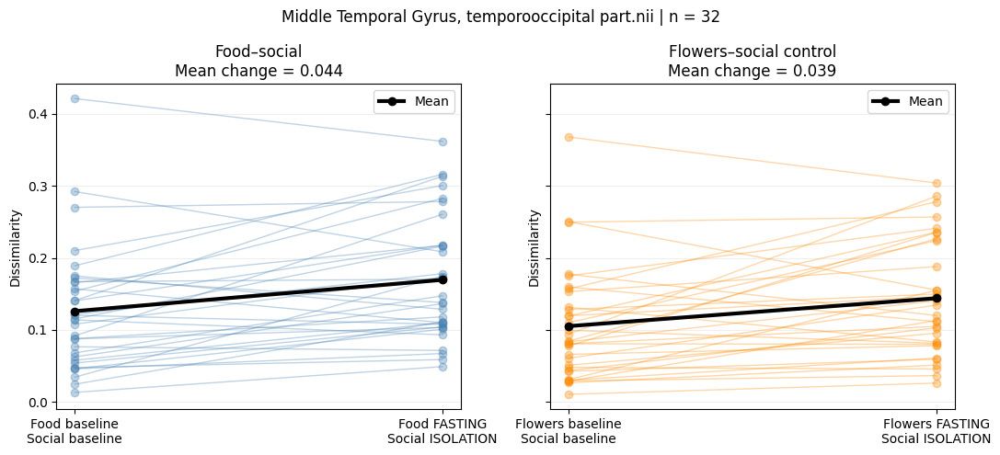

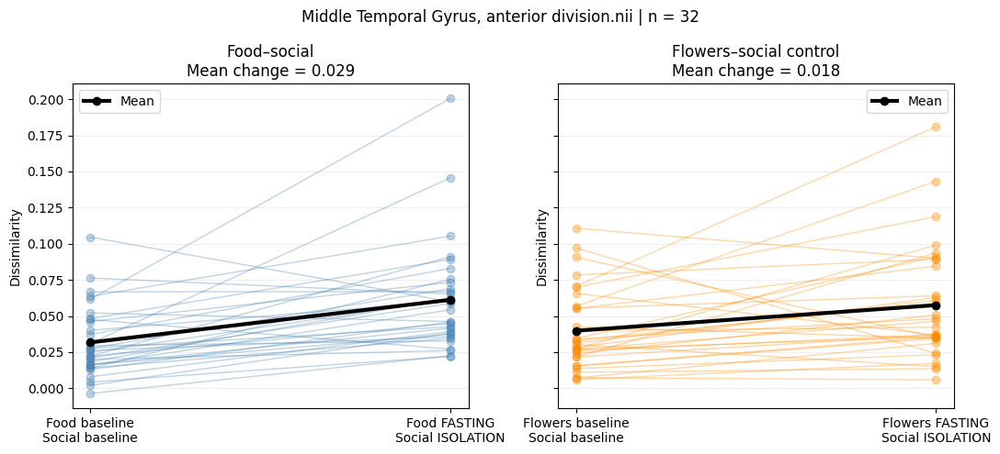

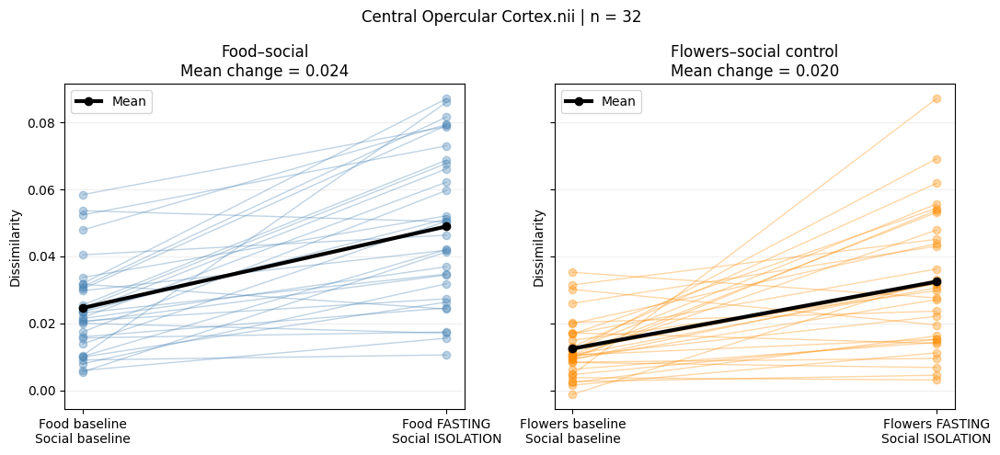

                                                                    ROI  n  food_change  control_change  difference_in_changes    p_food  p_change_difference  p_food_fdr  p_change_difference_fdr
                                                 Subcallosal Cortex.nii 21      0.01144        0.008446               0.002989 8.392e-05              0.02021   0.0001151                  0.05709
                                                            SNc_VTA.nii 28     0.009279         0.00653               0.002749    0.1236               0.6395       0.128                   0.8028
                                 Cingulate Gyrus, anterior division.nii 32      0.01073        0.009253               0.001474 6.457e-05                0.303   9.524e-05                    0.436
                                             Superior Frontal Gyrus.nii 32      0.02687         0.02209               0.004775 4.547e-07            0.0006532   1.412e-06                 0.005561
                         

In [47]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ttest_rel
from statsmodels.stats.multitest import multipletests

conds = [str(c) for c in rdms["conditions"]]

def find_condition(cue, state):
    matches = [
        i for i, label in enumerate(conds)
        if {cue, state}.issubset(label.lower().split("_"))
    ]
    if len(matches) != 1:
        raise ValueError(
            f"Expected one condition for {cue} + {state}. "
            f"Available labels: {conds}"
        )
    print(f"{cue}, {state}: {conds[matches[0]]}")
    return matches[0]

food_base = find_condition("food", "baseline")
food_fast = find_condition("food", "fasting")
social_base = find_condition("social", "baseline")
social_iso = find_condition("social", "isolation")
flowers_base = find_condition("flowers", "baseline")
flowers_fast = find_condition("flowers", "fasting")

results = []

for roi_idx, roi_name in enumerate(rdms["rois"]):
    values = []

    for subj_idx in range(len(rdms["subjects"])):
        rdm = rdms["rdms"][subj_idx, roi_idx]

        values.append([
            rdm[food_base, social_base],
            rdm[food_fast, social_iso],       # Cross-condition target
            rdm[flowers_base, social_base],
            rdm[flowers_fast, social_iso],    # Cross-condition control
        ])

    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values).all(axis=1)]

    if len(values) < 2:
        print(f"Skipping {roi_name}: insufficient complete pairs.")
        continue

    food_baseline, food_matched, control_baseline, control_matched = values.T

    food_change = food_matched - food_baseline
    control_change = control_matched - control_baseline

    # Does the food–social change differ from the flowers–social change?
    interaction = ttest_rel(food_change, control_change)

    results.append({
        "ROI": str(roi_name),
        "n": len(values),
        "food_change": food_change.mean(),
        "control_change": control_change.mean(),
        "difference_in_changes": (food_change - control_change).mean(),
        "p_food": ttest_rel(food_matched, food_baseline).pvalue,
        "p_change_difference": interaction.pvalue,
    })

    fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)

    panels = [
        (
            food_baseline, food_matched, "Food–social",
            ["Food baseline\nSocial baseline",
             "Food FASTING\nSocial ISOLATION"],
            "steelblue",
        ),
        (
            control_baseline, control_matched, "Flowers–social control",
            ["Flowers baseline\nSocial baseline",
             "Flowers FASTING\nSocial ISOLATION"],
            "darkorange",
        ),
    ]

    for ax, (baseline, matched, title, labels, color) in zip(axes, panels):
        for b, m in zip(baseline, matched):
            ax.plot(
                [0, 1], [b, m],
                "o-", color=color, alpha=0.35, linewidth=1,
            )

        ax.plot(
            [0, 1], [baseline.mean(), matched.mean()],
            "o-", color="black", linewidth=3, label="Mean",
        )

        ax.set_xticks([0, 1], labels)
        ax.set_title(
            f"{title}\nMean change = {(matched - baseline).mean():.3f}"
        )
        ax.set_ylabel("Dissimilarity")
        ax.grid(axis="y", alpha=0.2)
        ax.legend()

    fig.suptitle(f"{roi_name} | n = {len(values)}")
    plt.tight_layout()
    plt.show()

results_df = pd.DataFrame(results)

# Correct each family of tests across ROIs
if not results_df.empty:
    for column in ["p_food", "p_change_difference"]:
        results_df[column + "_fdr"] = np.nan
        valid = np.isfinite(results_df[column])

        if valid.any():
            results_df.loc[valid, column + "_fdr"] = multipletests(
                results_df.loc[valid, column],
                method="fdr_bh",
            )[1]

    print(results_df.to_string(index=False, float_format=lambda x: f"{x:.4g}"))

In [48]:
participant_scores

,atlas,subject,roi,model,rho,Loneliness_Score,Close_Relationships,Monthly_Interactions,Isolation_Lonely6
0,cortical,sub-SAXSISO01,Subcallosal Cortex,Social cues vs. food and flower cues,0.326222,42,17,40,47
1,cortical,sub-SAXSISO01,Subcallosal Cortex,Food cues vs. social and flower cues,-0.160437,42,17,40,47
2,cortical,sub-SAXSISO01,Subcallosal Cortex,Flower cues vs. social and food cues,-0.010696,42,17,40,47
3,cortical,sub-SAXSISO01,Subcallosal Cortex,Baseline vs. fasting and isolation,-0.213916,42,17,40,47
4,cortical,sub-SAXSISO01,Subcallosal Cortex,Isolation vs. baseline and fasting,0.074871,42,17,40,47
...,...,...,...,...,...,...,...,...,...
16618,cortical,sub-SAXSISO42,Central Opercular Cortex,Isolation vs. baseline and fasting,0.775445,43,6,41,50
16619,cortical,sub-SAXSISO42,Central Opercular Cortex,Fasting vs. baseline and isolation,0.240655,43,6,41,50
16620,cortical,sub-SAXSISO42,Central Opercular Cortex,Social cues after isolation vs. all other cond...,0.282999,43,6,41,50
16621,cortical,sub-SAXSISO42,Central Opercular Cortex,Food cues after fasting vs. all other conditions,0.057886,43,6,41,50


food, baseline: food_baseline
food, fasting: food_fasting
social, baseline: social_baseline
social, isolation: social_isolation
flowers, baseline: flowers_baseline
flowers, fasting: flowers_fasting
flowers, isolation: flowers_isolation


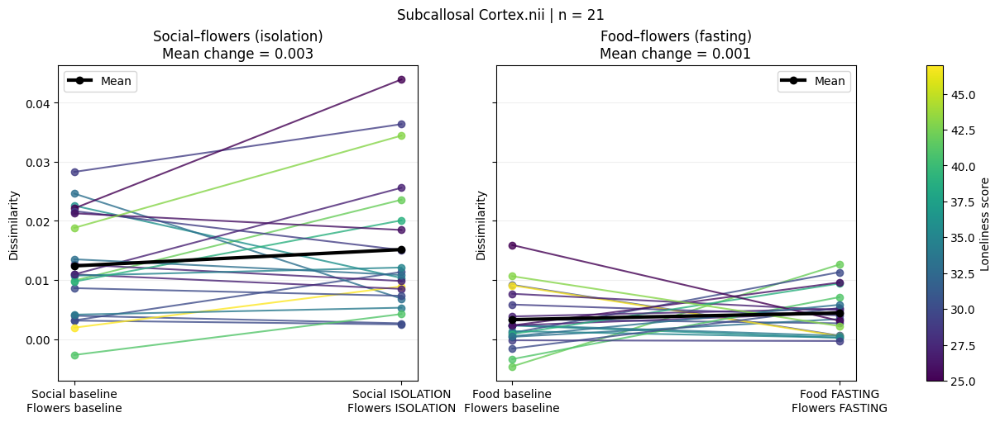

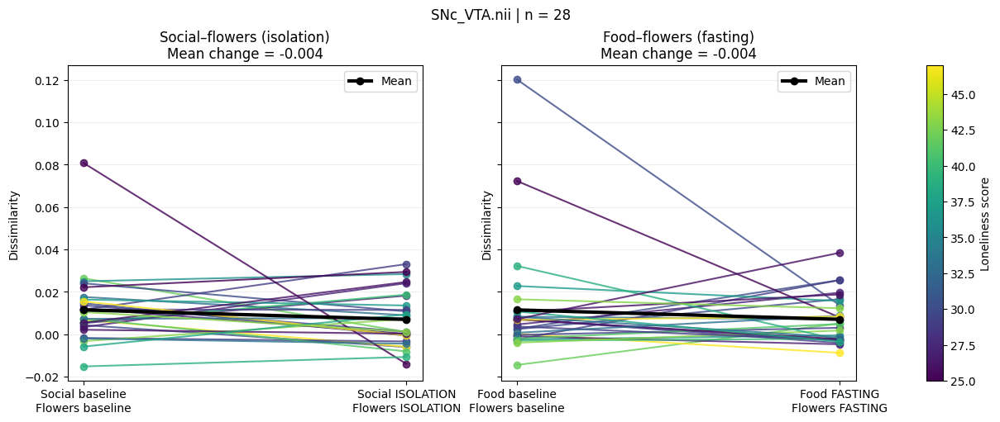

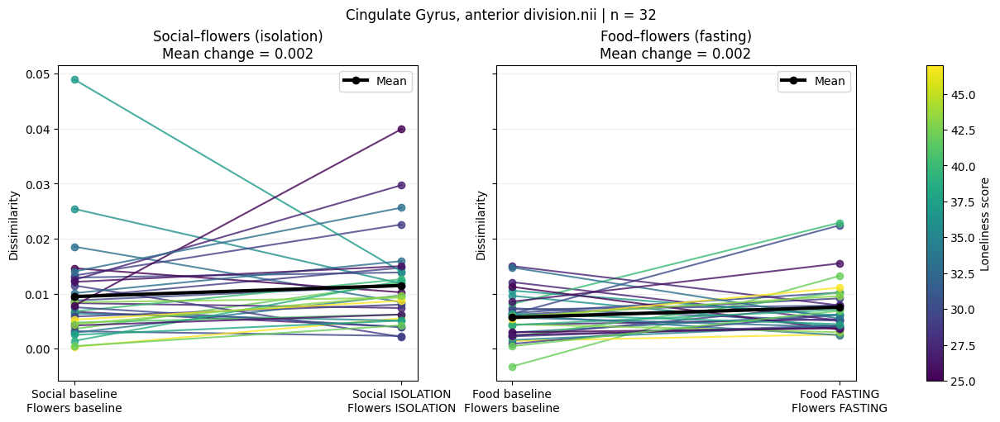

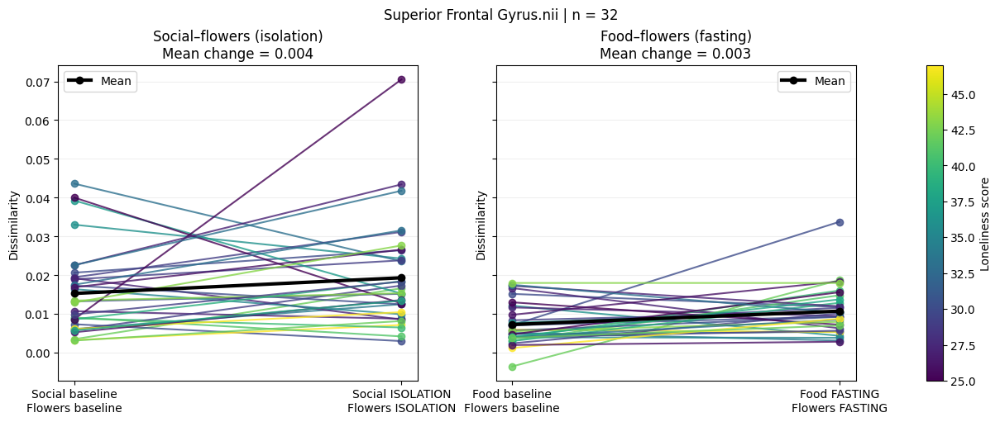

Skipping Temporal Fusiform Cortex, anterior division.nii: insufficient complete pairs.
Skipping HN.nii: insufficient complete pairs.


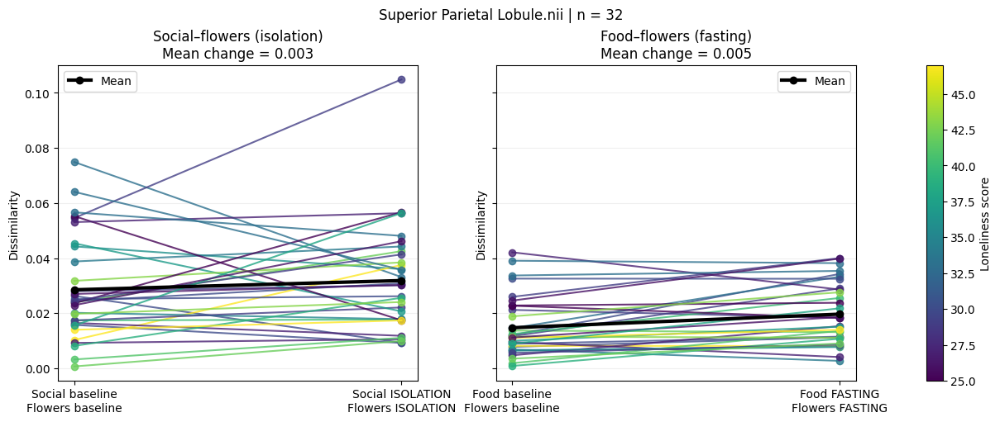

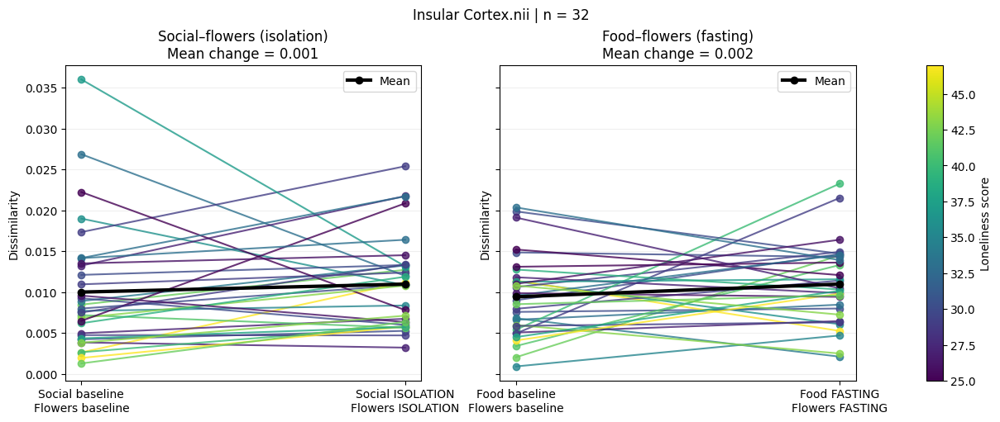

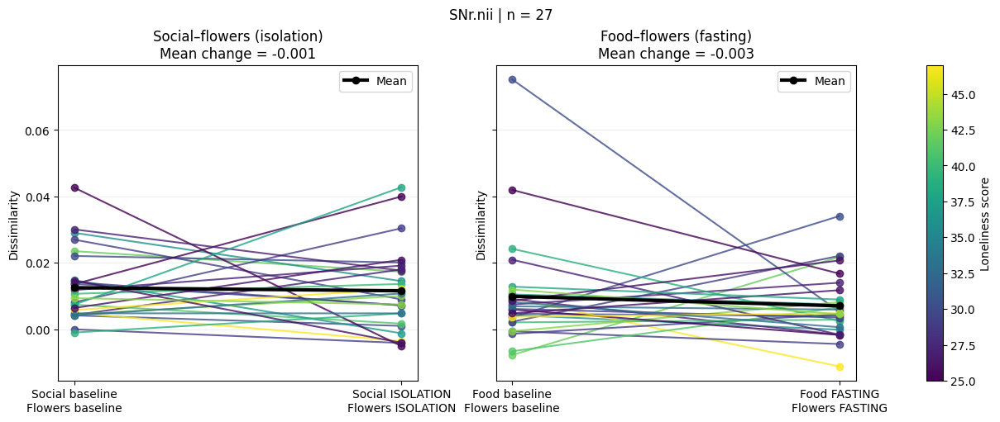

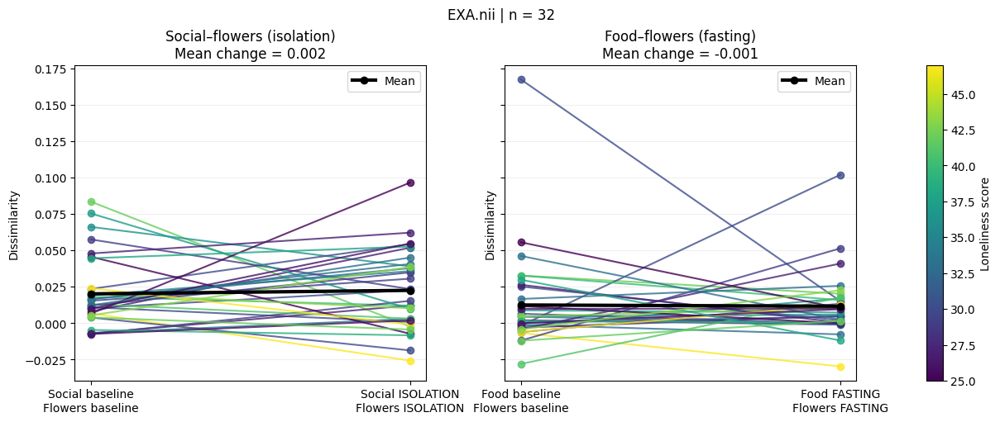

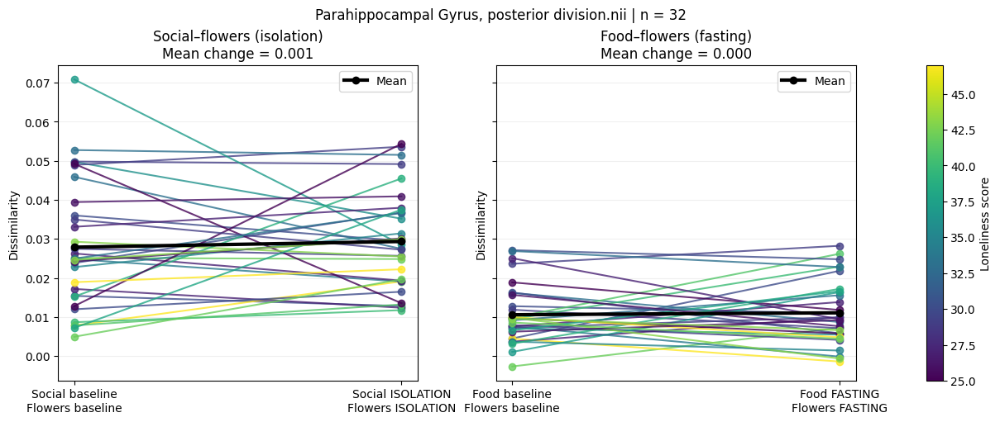

...

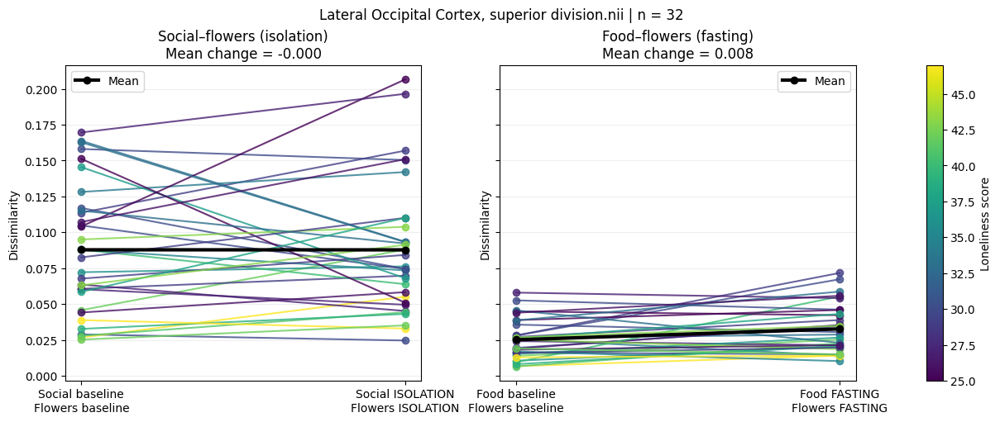

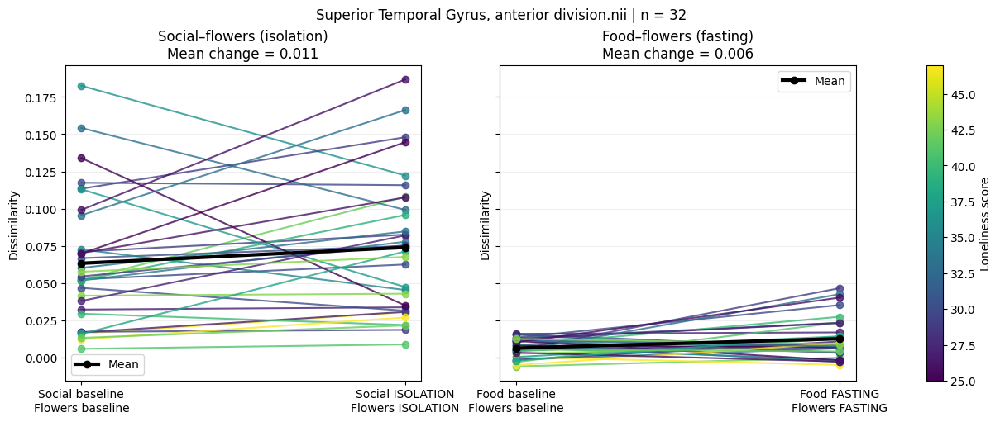

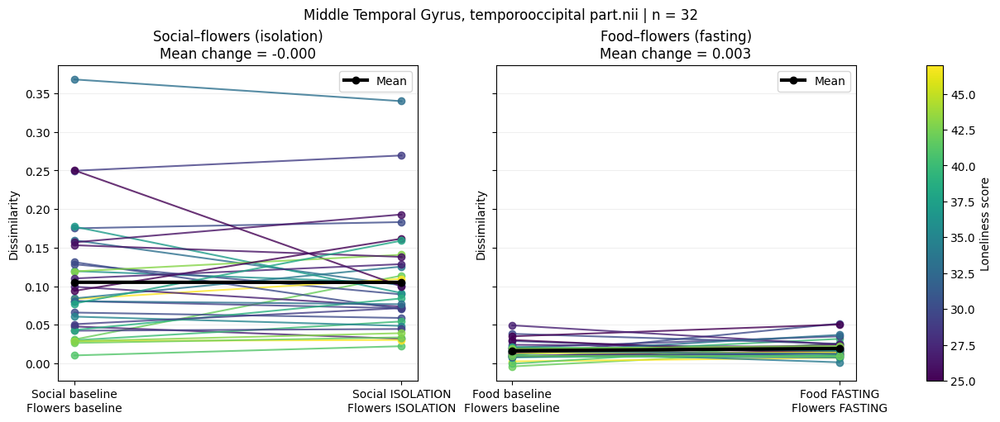

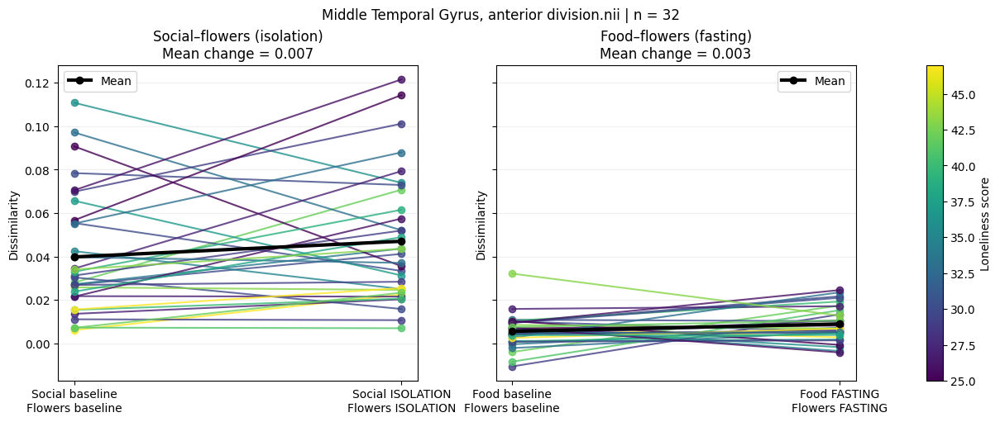

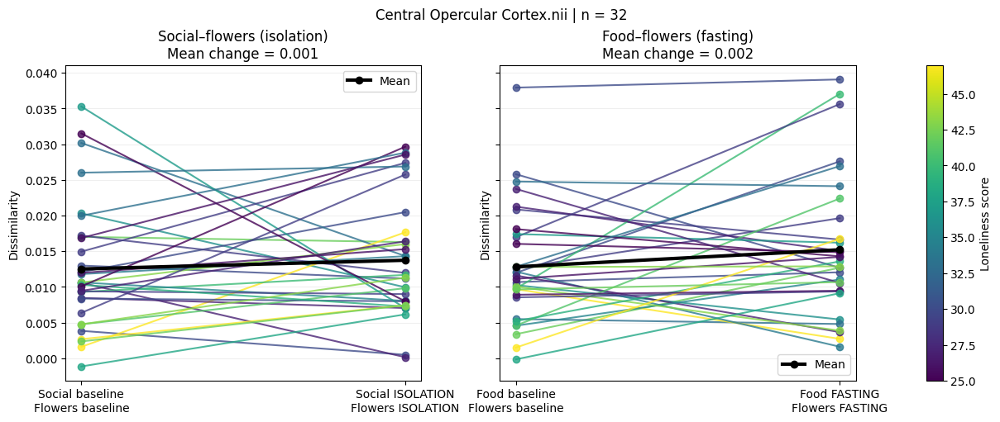

                                                                    ROI  n  isolation_change  fasting_change  difference_in_changes  p_isolation  p_fasting  p_change_difference  p_isolation_fdr  p_fasting_fdr  p_change_difference_fdr
                                                 Subcallosal Cortex.nii 21          0.002775        0.001127               0.001648       0.2002     0.4957               0.5564           0.8763         0.6647                   0.9655
                                                            SNc_VTA.nii 28         -0.004499       -0.004438             -6.041e-05       0.2828     0.3995               0.9905           0.8763         0.6202                   0.9905
                                 Cingulate Gyrus, anterior division.nii 32          0.002017         0.00185              0.0001669       0.2913     0.1139               0.9367           0.8763         0.2922                   0.9864
                                             Superior Frontal Gy

In [49]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ttest_rel
from statsmodels.stats.multitest import multipletests


# social_baseline and control_baseline VS social_isolation and control_isolation
# food_baseline and control_baseline VS food_fasting and control_fasting

conds = [str(c) for c in rdms["conditions"]]

def find_condition(cue, state):
    matches = [
        i for i, label in enumerate(conds)
        if {cue, state}.issubset(label.lower().split("_"))
    ]
    if len(matches) != 1:
        raise ValueError(
            f"Expected one condition for {cue} + {state}. "
            f"Available labels: {conds}"
        )
    print(f"{cue}, {state}: {conds[matches[0]]}")
    return matches[0]

food_base = find_condition("food", "baseline")
food_fast = find_condition("food", "fasting")
social_base = find_condition("social", "baseline")
social_iso = find_condition("social", "isolation")
flowers_base = find_condition("flowers", "baseline")
flowers_fast = find_condition("flowers", "fasting")
flowers_iso = find_condition("flowers", "isolation")

# Loneliness score per participant, used to color the lines
loneliness_by_subject = (
    behavioral_df.set_index("subject")["Loneliness_Score"]
    .astype(float)
    .reindex([str(s) for s in rdms["subjects"]])
)
loneliness_cmap = plt.cm.viridis
loneliness_norm = plt.Normalize(
    loneliness_by_subject.min(), loneliness_by_subject.max()
)

results = []

for roi_idx, roi_name in enumerate(rdms["rois"]):
    values = []

    for subj_idx in range(len(rdms["subjects"])):
        rdm = rdms["rdms"][subj_idx, roi_idx]

        values.append([
            rdm[social_base, flowers_base],
            rdm[social_iso, flowers_iso],       
            rdm[food_base, flowers_base],
            rdm[food_fast, flowers_fast],    
        ])

    values = np.asarray(values, dtype=float)
    complete = np.isfinite(values).all(axis=1)
    values = values[complete]
    loneliness = loneliness_by_subject.to_numpy()[complete]

    if len(values) < 2:
        print(f"Skipping {roi_name}: insufficient complete pairs.")
        continue

    social_base_pair, social_iso_pair, food_base_pair, food_fast_pair = values.T

    isolation_change = social_iso_pair - social_base_pair
    fasting_change = food_fast_pair - food_base_pair

    # Does the isolation change (social–flowers) differ from the fasting change (food–flowers)?
    interaction = ttest_rel(isolation_change, fasting_change)

    results.append({
        "ROI": str(roi_name),
        "n": len(values),
        "isolation_change": isolation_change.mean(),
        "fasting_change": fasting_change.mean(),
        "difference_in_changes": (isolation_change - fasting_change).mean(),
        "p_isolation": ttest_rel(social_iso_pair, social_base_pair).pvalue,
        "p_fasting": ttest_rel(food_fast_pair, food_base_pair).pvalue,
        "p_change_difference": interaction.pvalue,
    })

    fig, axes = plt.subplots(
        1, 2, figsize=(12, 5), sharey=True, layout="constrained"
    )

    panels = [
        (
            social_base_pair, social_iso_pair, "Social–flowers (isolation)",
            ["Social baseline\nFlowers baseline",
             "Social ISOLATION\nFlowers ISOLATION"],
        ),
        (
            food_base_pair, food_fast_pair, "Food–flowers (fasting)",
            ["Food baseline\nFlowers baseline",
             "Food FASTING\nFlowers FASTING"],
        ),
    ]

    for ax, (baseline, matched, title, labels) in zip(axes, panels):
        for b, m, score in zip(baseline, matched, loneliness):
            color = (
                loneliness_cmap(loneliness_norm(score))
                if np.isfinite(score) else "lightgrey"
            )
            ax.plot(
                [0, 1], [b, m],
                "o-", color=color, alpha=0.8, linewidth=1.5,
            )

        ax.plot(
            [0, 1], [baseline.mean(), matched.mean()],
            "o-", color="black", linewidth=3, label="Mean", zorder=3,
        )

        ax.set_xticks([0, 1], labels)
        ax.set_title(
            f"{title}\nMean change = {(matched - baseline).mean():.3f}"
        )
        ax.set_ylabel("Dissimilarity")
        ax.grid(axis="y", alpha=0.2)
        ax.legend()

    fig.colorbar(
        plt.cm.ScalarMappable(norm=loneliness_norm, cmap=loneliness_cmap),
        ax=axes, label="Loneliness score",
    )
    fig.suptitle(f"{roi_name} | n = {len(values)}")
    plt.show()

results_df = pd.DataFrame(results)

# Correct each family of tests across ROIs
if not results_df.empty:
    for column in ["p_isolation", "p_fasting", "p_change_difference"]:
        results_df[column + "_fdr"] = np.nan
        valid = np.isfinite(results_df[column])

        if valid.any():
            results_df.loc[valid, column + "_fdr"] = multipletests(
                results_df.loc[valid, column],
                method="fdr_bh",
            )[1]

    print(results_df.to_string(index=False, float_format=lambda x: f"{x:.4g}"))